# Few-Shot Learning for Bird Species Classification — Results Notebook

**Thesis:** Evaluation of Few-Shot Learning Paradigms for Bird Species Classification
**Dataset:** 20 bird species (15 base / 5 novel), ResNet-50 backbone
**Evaluation:** 5-way 1-shot episodic protocol on novel classes (600 episodes)

---
This notebook presents and compares all experimental results in sequence:
1. Dataset overview
2. Supervised Baseline — Full-20
3. Supervised Baseline — Base-15
4. ProtoNet (Euclidean) — main FSL result
5. ProtoNet Distance Ablation (Euclidean vs Manhattan)
6. Matching Networks
7. Relation Networks
8. Cross-model comparison & insights


In [81]:
%matplotlib inline
import os, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.ion()
plt.rcParams["figure.dpi"]  = 120
plt.rcParams["savefig.dpi"] = 150

NB_DIR = os.getcwd()
ROOT   = os.path.normpath(os.path.join(NB_DIR, '..'))
RES    = os.path.join(ROOT, 'results')
os.makedirs(RES, exist_ok=True)

print(f"ROOT : {ROOT}")
print(f"RES  : {RES}")
print(f"matplotlib backend: {matplotlib.get_backend()}")

PATHS = {
    # ── Baselines ──────────────────────────────────────────────────────────────
    'full20_json'          : f'{RES}/baseline/resnet50/full20/summary.json',
    'base15_json'          : f'{RES}/baseline/resnet50/base15/base_test/summary.json',
    # ── ProtoNet — all shots × distances ───────────────────────────────────────
    'proto_1shot_euc_json' : f'{RES}/proto_net/1shot_euclidean/summary.json',
    'proto_1shot_man_json' : f'{RES}/proto_net/1shot_manhattan/summary.json',
    'proto_3shot_euc_json' : f'{RES}/proto_net/3shot_euclidean/summary.json',
    'proto_3shot_man_json' : f'{RES}/proto_net/3shot_manhattan/summary.json',
    'proto_5shot_euc_json' : f'{RES}/proto_net/5shot_euclidean/summary.json',
    'proto_5shot_man_json' : f'{RES}/proto_net/5shot_manhattan/summary.json',
    # ── MatchingNet — all shots ────────────────────────────────────────────────
    'match_1shot_json'     : f'{RES}/matching_net/1shot/summary.json',
    'match_3shot_json'     : f'{RES}/matching_net/3shot/summary.json',
    'match_5shot_json'     : f'{RES}/matching_net/5shot/summary.json',
    # ── RelationNet — 1-shot only (3/5-shot pending) ──────────────────────────
    'rel_json'             : f'{RES}/relation_net/1shot/summary.json',
}

def load(key):
    path = PATHS[key]
    if not os.path.exists(path):
        return None
    with open(path) as f:
        return json.load(f)

def show_img(path, ax, title=None):
    if os.path.exists(path):
        ax.imshow(mpimg.imread(path))
        ax.axis('off')
        if title: ax.set_title(title, fontsize=10, fontweight='bold')
    else:
        ax.text(0.5, 0.5, f'Not found:\n{os.path.basename(path)}',
                ha='center', va='center', fontsize=9, color='gray', transform=ax.transAxes)
        ax.axis('off')

R = {k: load(k) for k in PATHS}
# Backward-compat aliases used by downstream cells
R['proto_euc_json'] = R['proto_1shot_euc_json']
R['proto_man_json'] = R['proto_1shot_man_json']
R['match_json']     = R['match_1shot_json']

print("\nSummary files status:")
skip = {'proto_euc_json', 'proto_man_json', 'match_json'}
for k, v in R.items():
    if k in skip: continue
    status = f"{v.get('accuracy', v.get('mean_accuracy_pct','?'))}" if v else "⚠️  NOT FOUND"
    print(f"  {k:<28s}: {status}")

ROOT : .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity
RES  : .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity\results
matplotlib backend: inline

Summary files status:
  full20_json                 : 0.99
  base15_json                 : 1.0
  proto_1shot_euc_json        : 94.1067
  proto_1shot_man_json        : 78.9467
  proto_3shot_euc_json        : 99.2267
  proto_3shot_man_json        : 90.1933
  proto_5shot_euc_json        : 99.9067
  proto_5shot_man_json        : 93.2467
  match_1shot_json            : 60.9
  match_3shot_json            : 69.0
  match_5shot_json            : 70.78
  rel_json                    : 72.66


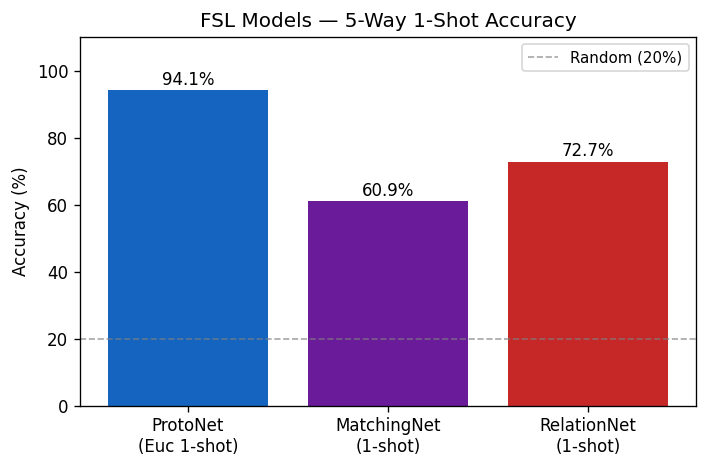

In [82]:
# Quick plot test — renders dynamically from loaded results
models = ['ProtoNet\n(Euc 1-shot)', 'MatchingNet\n(1-shot)', 'RelationNet\n(1-shot)']
accs   = [
    R['proto_1shot_euc_json']['mean_accuracy_pct'],
    R['match_1shot_json']['mean_accuracy_pct'],
    R['rel_json']['mean_accuracy_pct'],
]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(models, accs, color=['#1565C0', '#6A1B9A', '#C62828'])
for bar, v in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.5, f'{v:.1f}%', ha='center', va='bottom', fontsize=10)
ax.axhline(y=20, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='Random (20%)')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 110)
ax.set_title('FSL Models — 5-Way 1-Shot Accuracy')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

---
## 1. Dataset Overview

**20 bird species** split into base (15) and novel (5) classes.
Base classes are used for supervised training; novel classes are held out for few-shot evaluation.


In [83]:
# Dataset summary table
BASE = [
    'ABBOTTS BABBLER','ABBOTTS BOOBY','ABYSSINIAN GROUND HORNBILL',
    'AFRICAN CROWNED CRANE','AFRICAN EMERALD CUCKOO','AFRICAN FIREFINCH',
    'AFRICAN OYSTER CATCHER','AFRICAN PIED HORNBILL','AFRICAN PYGMY GOOSE',
    'ALBATROSS','ALBERTS TOWHEE','ALEXANDRINE PARAKEET',
    'ALPINE CHOUGH','ALTAMIRA YELLOWTHROAT','AMERICAN AVOCET'
]
NOVEL = ['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO',
         'AMERICAN GOLDFINCH','AMERICAN KESTREL']

TRAIN_COUNTS = {
    'ABBOTTS BABBLER':166,'ABBOTTS BOOBY':180,'ABYSSINIAN GROUND HORNBILL':179,
    'AFRICAN CROWNED CRANE':137,'AFRICAN EMERALD CUCKOO':154,'AFRICAN FIREFINCH':137,
    'AFRICAN OYSTER CATCHER':155,'AFRICAN PIED HORNBILL':187,'AFRICAN PYGMY GOOSE':179,
    'ALBATROSS':133,'ALBERTS TOWHEE':161,'ALEXANDRINE PARAKEET':165,
    'ALPINE CHOUGH':166,'ALTAMIRA YELLOWTHROAT':150,'AMERICAN AVOCET':179,
    'AMERICAN BITTERN':170,'AMERICAN COOT':158,'AMERICAN FLAMINGO':164,
    'AMERICAN GOLDFINCH':133,'AMERICAN KESTREL':155
}

df_ds = pd.DataFrame({
    'Class': BASE + NOVEL,
    'Role':  ['Base']*15 + ['Novel']*5,
    'Train Images': [TRAIN_COUNTS[c] for c in BASE + NOVEL],
    'Val Images':  [5]*20,
    'Test Images': [5]*20,
})
df_ds['Total'] = df_ds['Train Images'] + df_ds['Val Images'] + df_ds['Test Images']

print(f"Base classes : {len(BASE)}   |  Novel classes : {len(NOVEL)}")
print(f"Train images : {df_ds['Train Images'].sum()}  |  Val : {df_ds['Val Images'].sum()}  |  Test : {df_ds['Test Images'].sum()}")
print()
display(df_ds.style
    .applymap(lambda v: 'background-color:#0bf007;font-weight:bold' if v=='Base' else
              ('background-color:#f55142;font-weight:bold' if v=='Novel' else ''),
              subset=['Role'])
    .set_caption('Dataset Split: Base vs Novel Classes')
    .format({'Train Images': '{:d}', 'Val Images': '{:d}', 'Test Images': '{:d}', 'Total': '{:d}'})
)


Base classes : 15   |  Novel classes : 5
Train images : 3208  |  Val : 100  |  Test : 100



,Class,Role,Train Images,Val Images,Test Images,Total
0,ABBOTTS BABBLER,Base,166,5,5,176
1,ABBOTTS BOOBY,Base,180,5,5,190
2,ABYSSINIAN GROUND HORNBILL,Base,179,5,5,189
3,AFRICAN CROWNED CRANE,Base,137,5,5,147
4,AFRICAN EMERALD CUCKOO,Base,154,5,5,164
5,AFRICAN FIREFINCH,Base,137,5,5,147
6,AFRICAN OYSTER CATCHER,Base,155,5,5,165
7,AFRICAN PIED HORNBILL,Base,187,5,5,197
8,AFRICAN PYGMY GOOSE,Base,179,5,5,189
9,ALBATROSS,Base,133,5,5,143


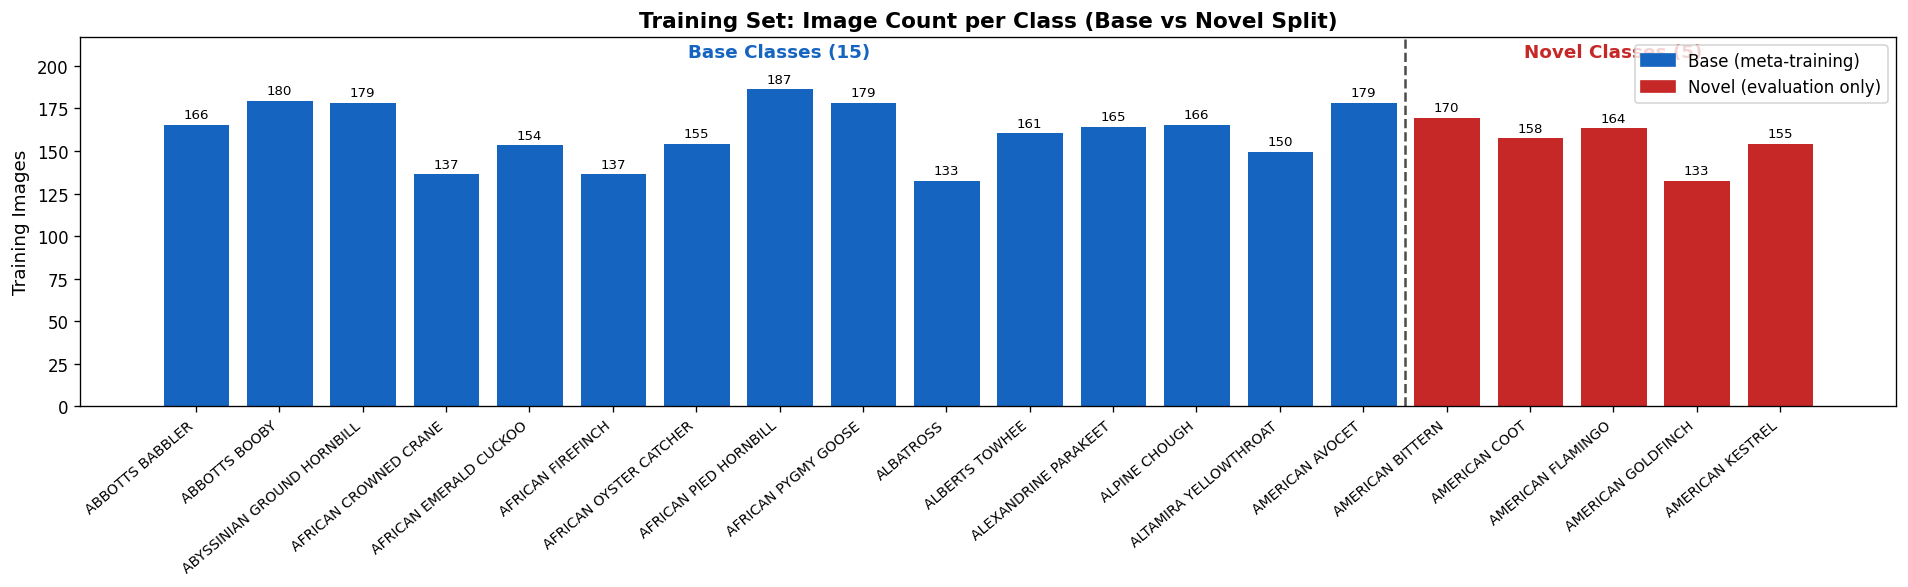

In [84]:
# Training image count bar chart — base/novel coloured
BASE_COL, NOVEL_COL = '#1565C0', '#C62828'
all_classes = BASE + NOVEL
counts = [TRAIN_COUNTS[c] for c in all_classes]
colors = [BASE_COL]*15 + [NOVEL_COL]*5

fig, ax = plt.subplots(figsize=(16, 5))
bars = ax.bar(range(20), counts, color=colors, edgecolor='white', linewidth=0.6)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
ax.set_xticks(range(20))
ax.set_xticklabels(all_classes, rotation=40, ha='right', fontsize=8.5)
ax.axvline(x=14.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax.text(7,  max(counts)+18, 'Base Classes (15)', ha='center', fontsize=11,
        color=BASE_COL, fontweight='bold')
ax.text(17, max(counts)+18, 'Novel Classes (5)',  ha='center', fontsize=11,
        color=NOVEL_COL, fontweight='bold')
ax.legend(handles=[Patch(color=BASE_COL, label='Base (meta-training)'),
                   Patch(color=NOVEL_COL, label='Novel (evaluation only)')], fontsize=10)
ax.set_title('Training Set: Image Count per Class (Base vs Novel Split)', fontsize=13, fontweight='bold')
ax.set_ylabel('Training Images', fontsize=11)
ax.set_ylim(0, max(counts)+30)
plt.tight_layout()
plt.savefig('../results/dataset_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 2. Supervised Baseline — Full-20

ResNet-50 trained on **all 20 classes** (supervised, no few-shot protocol).
Serves as an upper-bound reference — the model has seen all classes during training.

> ⚠️ **Note:** Val/test sets are very small (5 images per class = 100 total).
> Results should be interpreted with caution — the 95% CI is wide.
> Epoch count is read from `summary.json` and shown dynamically below.

In [85]:
r = R['full20_json']
ci = r['accuracy_ci_95']
print("=" * 55)
print(f"  Full-20 Supervised Baseline — Test Set Results")
print("=" * 55)
print(f"  Test images     : {r['test_images']}  ({r['num_classes']} classes × 5 images)")
print(f"  Epochs trained  : {r['epochs_trained']}")
print(f"  Accuracy        : {r['accuracy']*100:.2f}%")
print(f"  95% Wilson CI   : [{ci[0]*100:.2f}%, {ci[1]*100:.2f}%]")
print(f"  Macro F1        : {r['macro_f1']:.4f}")
print(f"  Macro Precision : {r['macro_precision']:.4f}")
print(f"  Macro Recall    : {r['macro_recall']:.4f}")
print(f"  Macro AUC (OvR) : {r['macro_auc_ovr']:.4f}")
print(f"  Best Val Acc    : {r['val_acc_best']*100:.2f}%")


  Full-20 Supervised Baseline — Test Set Results
  Test images     : 100  (20 classes × 5 images)
  Epochs trained  : 3
  Accuracy        : 99.00%
  95% Wilson CI   : [94.55%, 99.82%]
  Macro F1        : 0.9899
  Macro Precision : 0.9917
  Macro Recall    : 0.9900
  Macro AUC (OvR) : 1.0000
  Best Val Acc    : 100.00%


In [86]:
# Full-20 — Classification report
cr_path = f'{RES}/baseline/resnet50/full20/classification_report.csv'
df_cr = pd.read_csv(cr_path, index_col=0)
print("Per-class classification report (Full-20):")
display(df_cr.style
    .background_gradient(cmap='Blues', subset=['f1-score','precision','recall'], vmin=0, vmax=1)
    .format('{:.3f}', subset=['f1-score','precision','recall'])
    .set_caption('Full-20 Baseline: Per-Class Metrics')
)


Per-class classification report (Full-20):


,precision,recall,f1-score,support
ABBOTTS BABBLER,1.000,1.000,1.000,5.000000
ABBOTTS BOOBY,1.000,1.000,1.000,5.000000
ABYSSINIAN GROUND HORNBILL,1.000,1.000,1.000,5.000000
AFRICAN CROWNED CRANE,1.000,1.000,1.000,5.000000
AFRICAN EMERALD CUCKOO,1.000,1.000,1.000,5.000000
AFRICAN FIREFINCH,1.000,1.000,1.000,5.000000
AFRICAN OYSTER CATCHER,1.000,1.000,1.000,5.000000
AFRICAN PIED HORNBILL,0.833,1.000,0.909,5.000000
AFRICAN PYGMY GOOSE,1.000,1.000,1.000,5.000000
ALBATROSS,1.000,1.000,1.000,5.000000


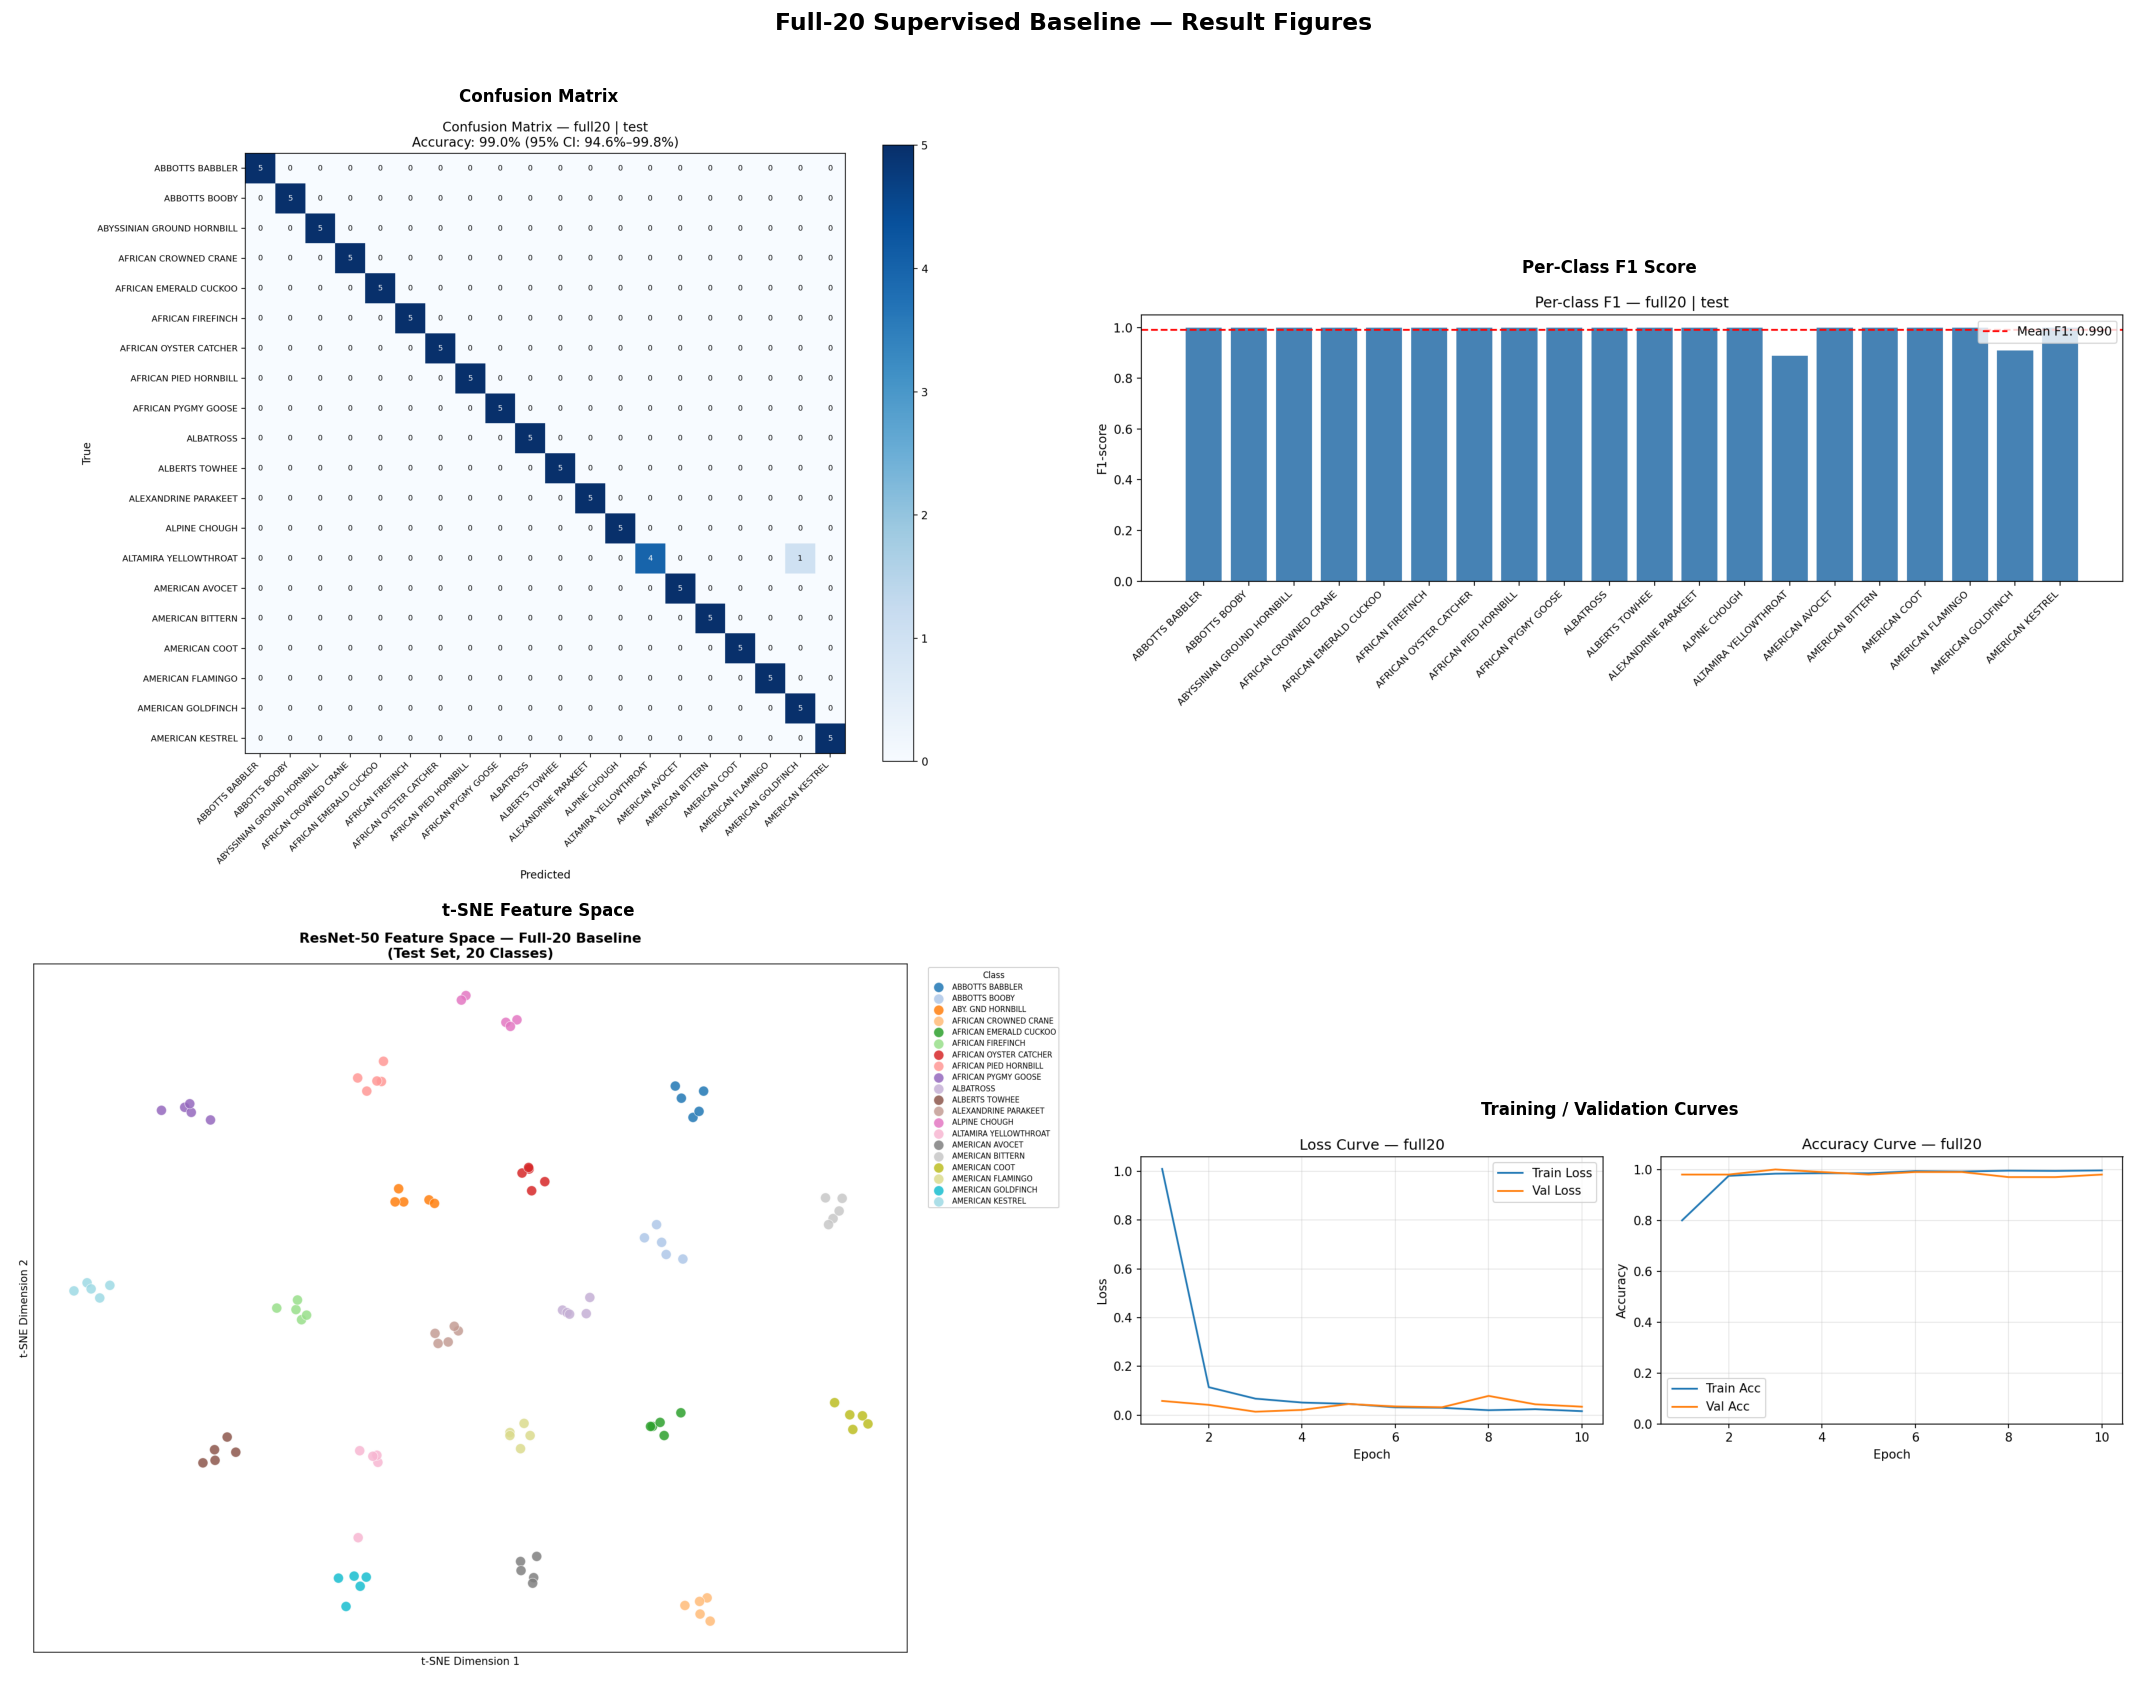

In [87]:
# Full-20 — Figures: confusion matrix, F1 per class, t-SNE, learning curves
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

base_path = f'{RES}/baseline/resnet50/full20'
show_img(f'{base_path}/confusion_matrix.png',  axes[0], 'Confusion Matrix')
show_img(f'{base_path}/f1_per_class.png',       axes[1], 'Per-Class F1 Score')
show_img(f'{base_path}/tsne_features.png',      axes[2], 't-SNE Feature Space')
show_img(f'{base_path}/learning_curves.png',    axes[3], 'Training / Validation Curves')

plt.suptitle('Full-20 Supervised Baseline — Result Figures', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/full20_results_panel.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 3. Supervised Baseline — Base-15

ResNet-50 trained on **15 base classes only** (the FSL meta-training set).
This model is **never shown the novel classes** during training — its performance on base classes
shows the quality of the learned feature space before few-shot adaptation.


In [88]:
r = R['base15_json']
ci = r['accuracy_ci_95']
print("=" * 55)
print(f"  Base-15 Supervised Baseline — Test Set Results")
print("=" * 55)
print(f"  Test images     : {r['test_images']}  (15 base classes × 5 images)")
print(f"  Epochs trained  : {r['epochs_trained']}")
print(f"  Accuracy        : {r['accuracy']*100:.2f}%")
print(f"  95% Wilson CI   : [{ci[0]*100:.2f}%, {ci[1]*100:.2f}%]")
print(f"  Macro F1        : {r['macro_f1']:.4f}")
print(f"  Macro Precision : {r['macro_precision']:.4f}")
print(f"  Macro Recall    : {r['macro_recall']:.4f}")
print(f"  Macro AUC (OvR) : {r['macro_auc_ovr']:.4f}")
print(f"  Best Val Acc    : {r['val_acc_best']*100:.2f}%")


  Base-15 Supervised Baseline — Test Set Results
  Test images     : 75  (15 base classes × 5 images)
  Epochs trained  : 2
  Accuracy        : 100.00%
  95% Wilson CI   : [95.13%, 100.00%]
  Macro F1        : 1.0000
  Macro Precision : 1.0000
  Macro Recall    : 1.0000
  Macro AUC (OvR) : 1.0000
  Best Val Acc    : 100.00%


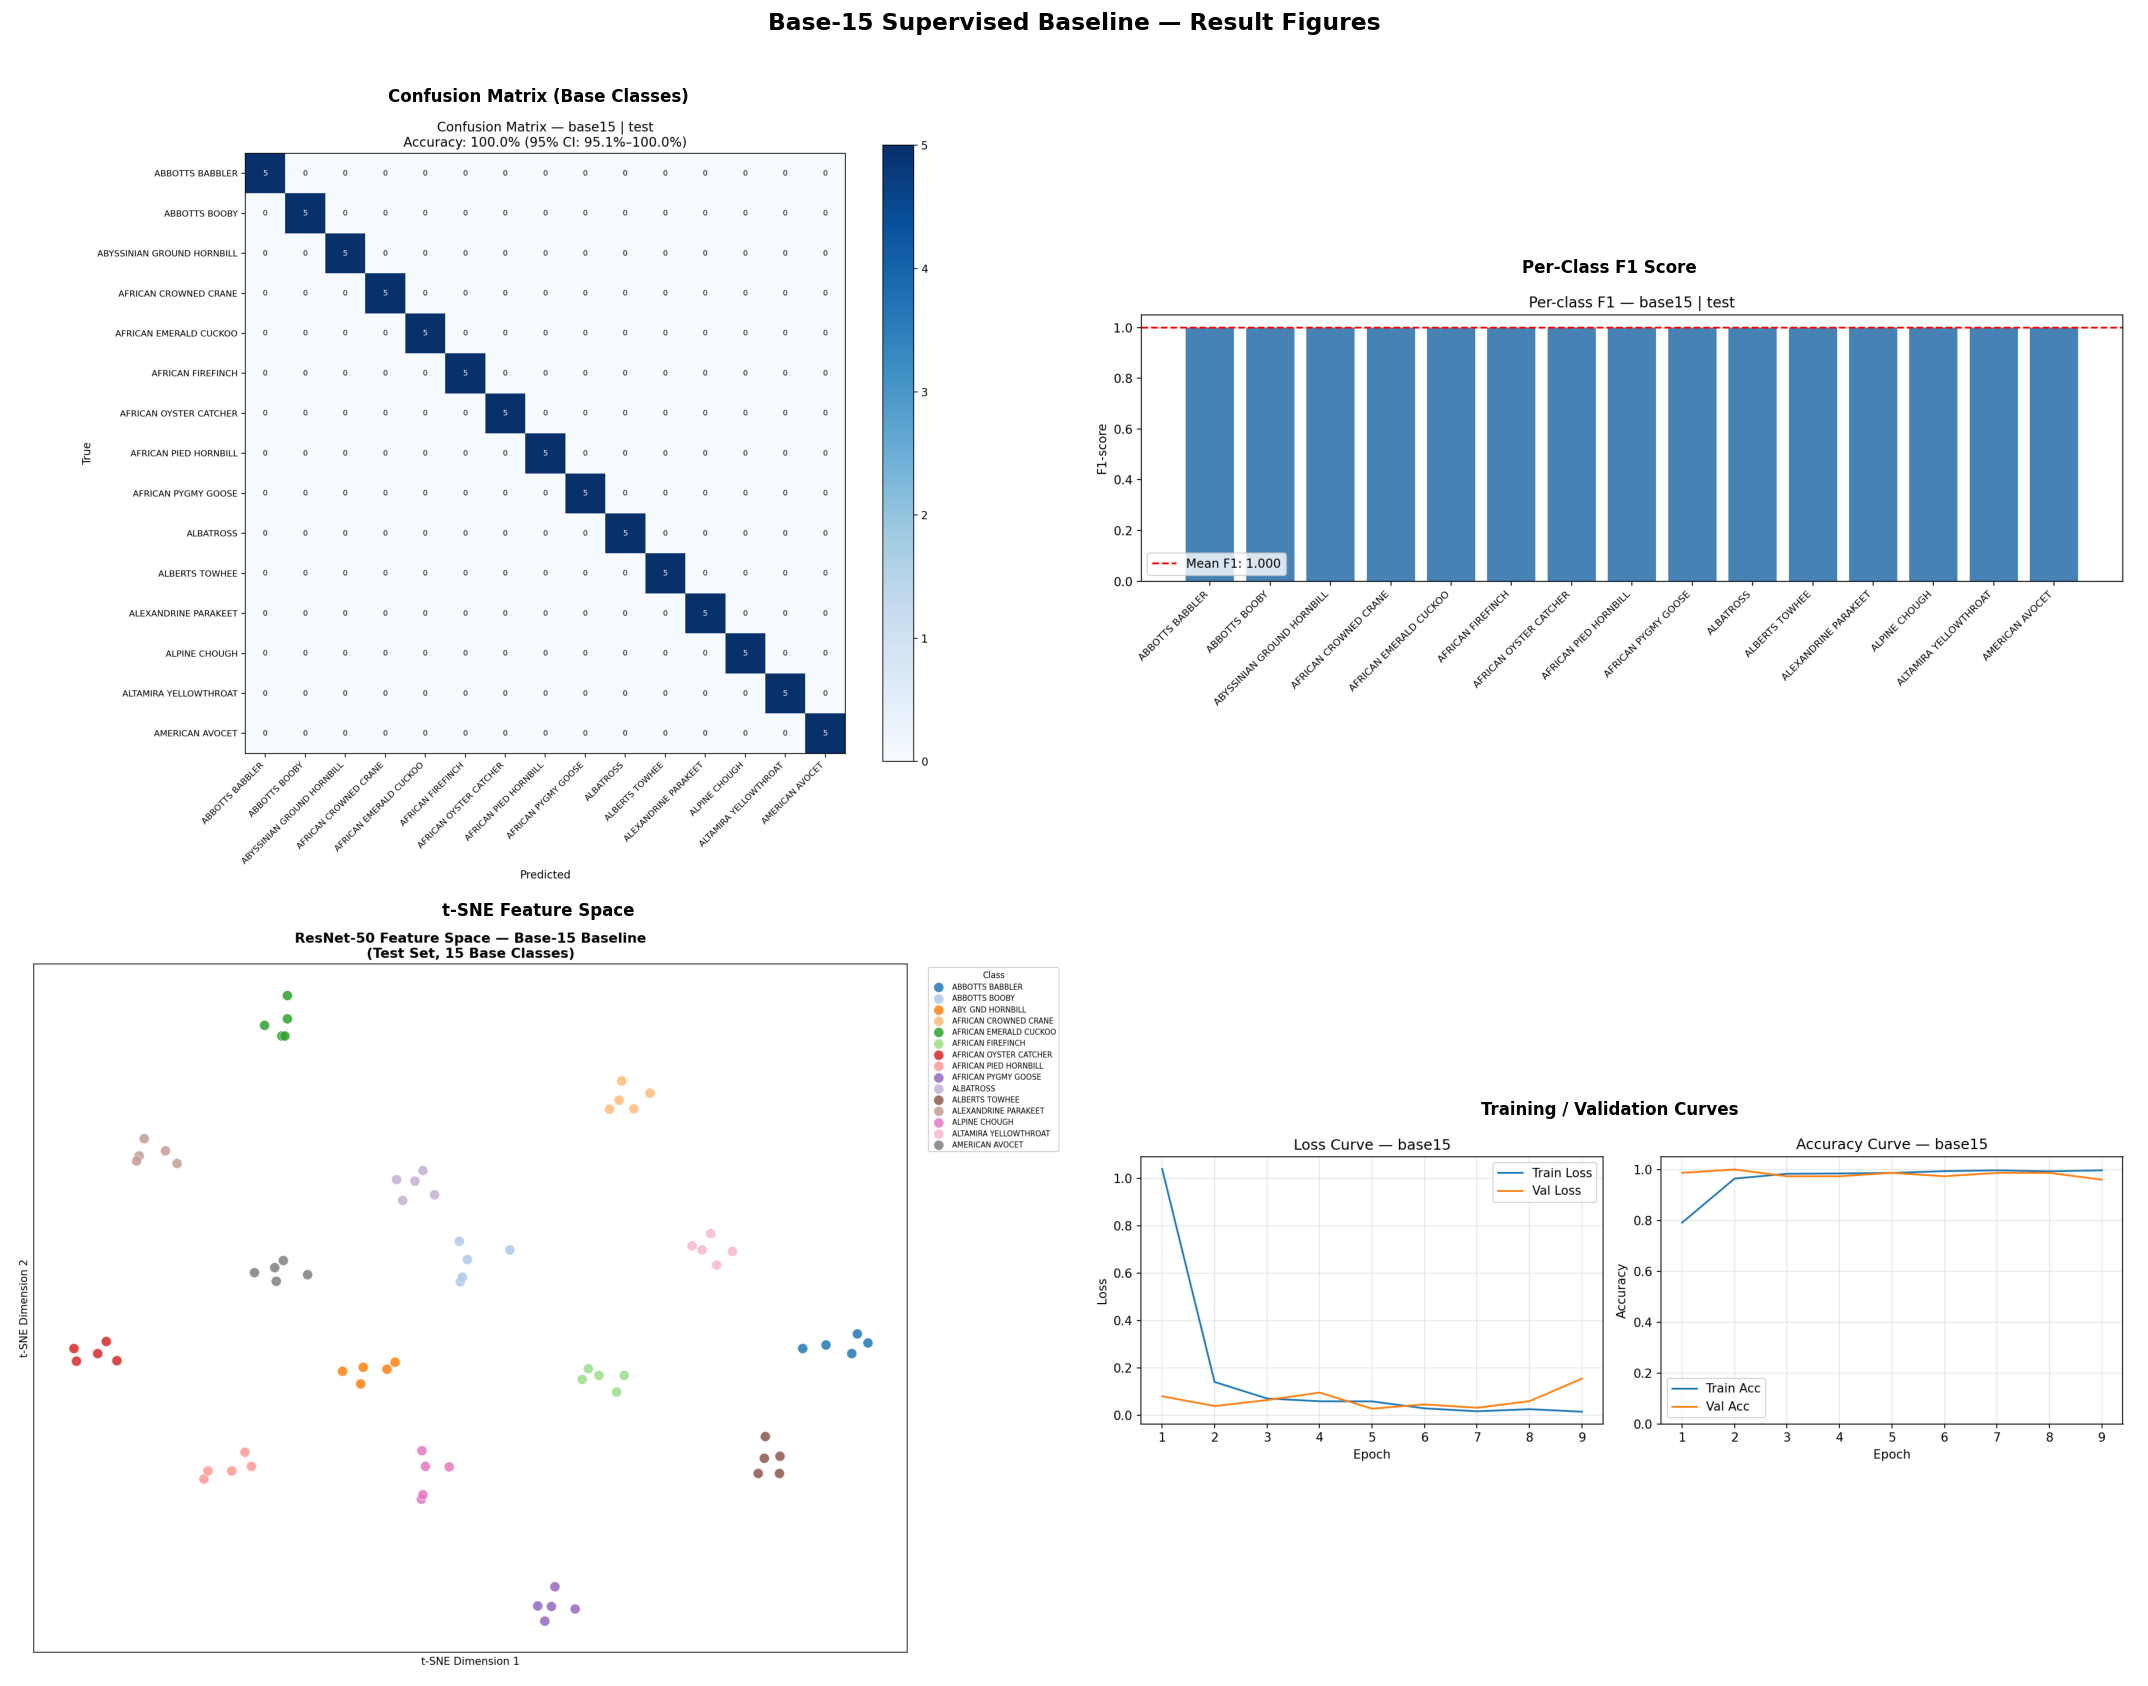

In [89]:
# Base-15 — Figures panel
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

base_path = f'{RES}/baseline/resnet50/base15/base_test'
show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix (Base Classes)')
show_img(f'{base_path}/f1_per_class.png',      axes[1], 'Per-Class F1 Score')
show_img(f'{base_path}/tsne_features.png',     axes[2], 't-SNE Feature Space')
show_img(f'{base_path}/learning_curves.png',   axes[3], 'Training / Validation Curves')

plt.suptitle('Base-15 Supervised Baseline — Result Figures', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/base15_results_panel.png', dpi=150, bbox_inches='tight')
plt.show()


In [90]:
from IPython.display import display, Markdown
_r = R['proto_euc_json']
display(Markdown(f"""---
## 4. Prototypical Networks — 5-Way {_r['k_shot']}-Shot (Euclidean, {_r['num_episodes']} Episodes)

**Main FSL result.** ProtoNet computes a prototype (mean embedding) per class from
the support set, then classifies query images by nearest-prototype distance.

- **Protocol:** {_r['n_way']}-way {_r['k_shot']}-shot, {_r['num_episodes']} random episodes
- **Query set:** all 5 novel TEST images per class (fixed, no data leakage)
- **Distance:** Euclidean (L2) — as in the original ProtoNet paper (Snell et al., 2017)
- **Reliability:** {"✅ High — statistically reliable" if _r['num_episodes'] >= 100 else f"⚠️ Low — only {_r['num_episodes']} episodes"}
"""))

---
## 4. Prototypical Networks — 5-Way 1-Shot (Euclidean, 600 Episodes)

**Main FSL result.** ProtoNet computes a prototype (mean embedding) per class from
the support set, then classifies query images by nearest-prototype distance.

- **Protocol:** 5-way 1-shot, 600 random episodes
- **Query set:** all 5 novel TEST images per class (fixed, no data leakage)
- **Distance:** Euclidean (L2) — as in the original ProtoNet paper (Snell et al., 2017)
- **Reliability:** ✅ High — statistically reliable


In [91]:
# ProtoNet — all shots × distances summary table
SHOTS = [1, 3, 5]
DIST_MAP = {'euc': 'Euclidean (L2)', 'man': 'Manhattan (L1)'}

rows_proto = []
for shot in SHOTS:
    for dist_key, dist_label in DIST_MAP.items():
        key = f'proto_{shot}shot_{dist_key}_json'
        r = R.get(key)
        if r is None:
            continue
        ci = r['wilson_ci_95']
        rows_proto.append({
            'K-Shot'      : f'{shot}-shot',
            'Distance'    : dist_label,
            'Episodes'    : r['num_episodes'],
            'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
            '95% CI ±'    : round(r['ci95_pct'], 2),
            'Wilson CI'   : f"[{ci[0]:.2f}%, {ci[1]:.2f}%]",
            'Macro F1'    : round(r['macro_f1'], 4),
            'Std (%)'     : round(r['std_accuracy_pct'], 2),
        })

df_proto = pd.DataFrame(rows_proto)
print("ProtoNet — 5-Way, All Shot Configurations (600 episodes each)")
display(df_proto.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=50, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Macro F1': '{:.4f}', 'Std (%)': '{:.2f}'})
    .set_caption('ProtoNet — All Shots × Distances (5-way, 600 episodes each)')
)

# Per-class accuracy comparison across shots (Euclidean)
print("\nPer-class accuracy — Euclidean, all shots:")
novel_classes = list(R['proto_1shot_euc_json']['per_class_accuracy_pct'].keys())
df_pc = pd.DataFrame({'Class': novel_classes})
for shot in SHOTS:
    r = R.get(f'proto_{shot}shot_euc_json')
    if r:
        df_pc[f'{shot}-shot (%)'] = [round(r['per_class_accuracy_pct'][c], 2) for c in novel_classes]
acc_cols = [c for c in df_pc.columns if 'shot' in c]
display(df_pc.style
    .background_gradient(cmap='RdYlGn', subset=acc_cols, vmin=0, vmax=100)
    .format({c: '{:.2f}%' for c in acc_cols})
    .set_caption('ProtoNet (Euclidean) — Per-Class Accuracy by K-Shot')
)

ProtoNet — 5-Way, All Shot Configurations (600 episodes each)


,K-Shot,Distance,Episodes,Mean Acc (%),95% CI ±,Wilson CI,Macro F1,Std (%)
0,1-shot,Euclidean (L2),600,94.11,0.66,"[93.72%, 94.47%]",0.9403,8.27
1,1-shot,Manhattan (L1),600,78.95,1.07,"[78.29%, 79.59%]",0.7854,13.38
2,3-shot,Euclidean (L2),600,99.23,0.25,"[99.07%, 99.35%]",0.9923,3.14
3,3-shot,Manhattan (L1),600,90.19,0.72,"[89.71%, 90.66%]",0.9004,8.98
4,5-shot,Euclidean (L2),600,99.91,0.06,"[99.84%, 99.94%]",0.9991,0.79
5,5-shot,Manhattan (L1),600,93.25,0.61,"[92.83%, 93.64%]",0.9314,7.56



Per-class accuracy — Euclidean, all shots:


,Class,1-shot (%),3-shot (%),5-shot (%)
0,AMERICAN BITTERN,92.10%,100.00%,100.00%
1,AMERICAN COOT,98.73%,100.00%,100.00%
2,AMERICAN FLAMINGO,98.63%,98.30%,100.00%
3,AMERICAN GOLDFINCH,98.53%,100.00%,100.00%
4,AMERICAN KESTREL,82.53%,97.83%,99.53%


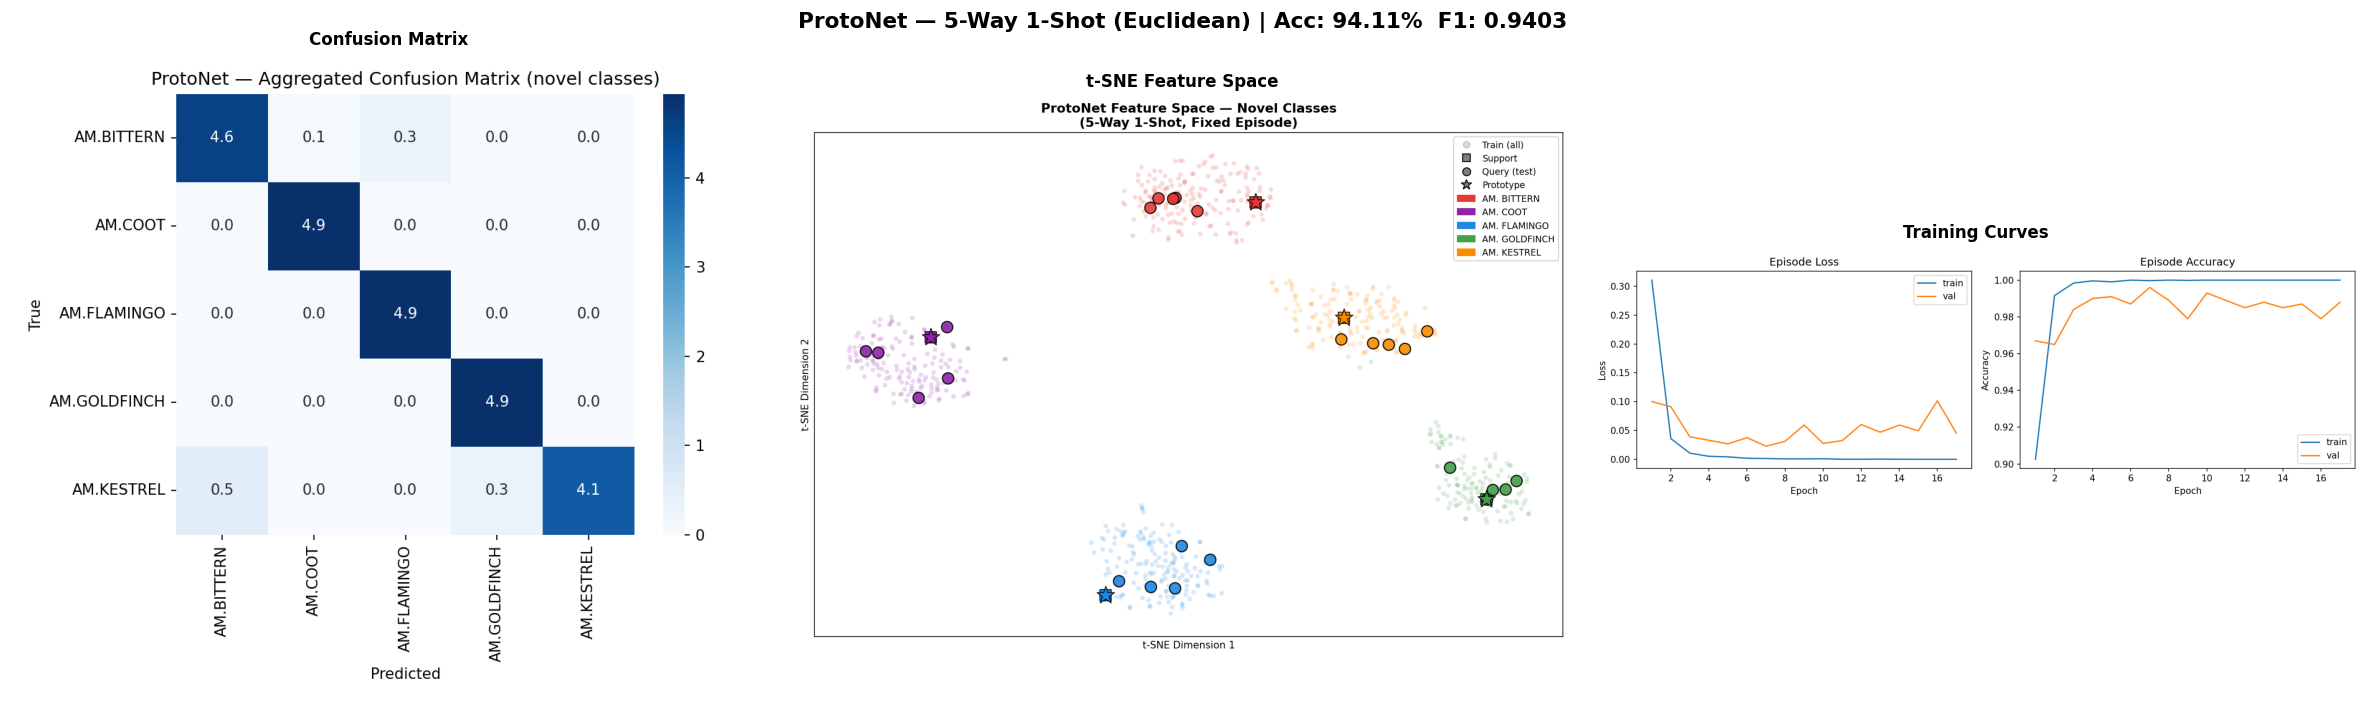

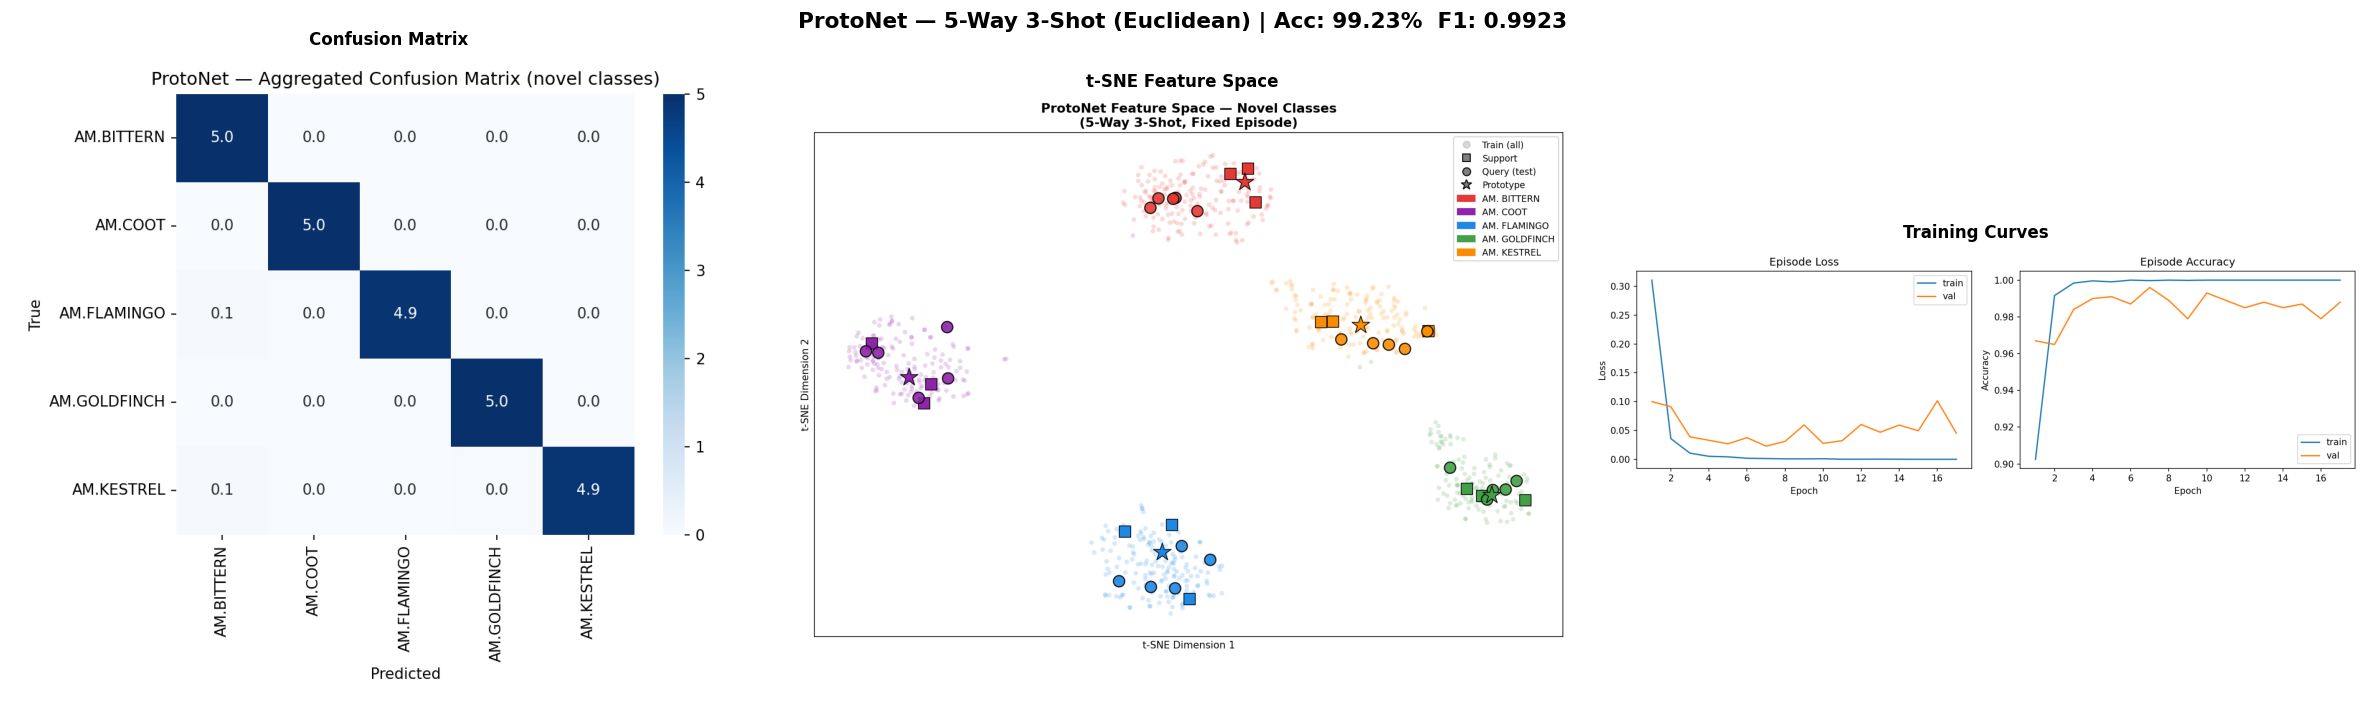

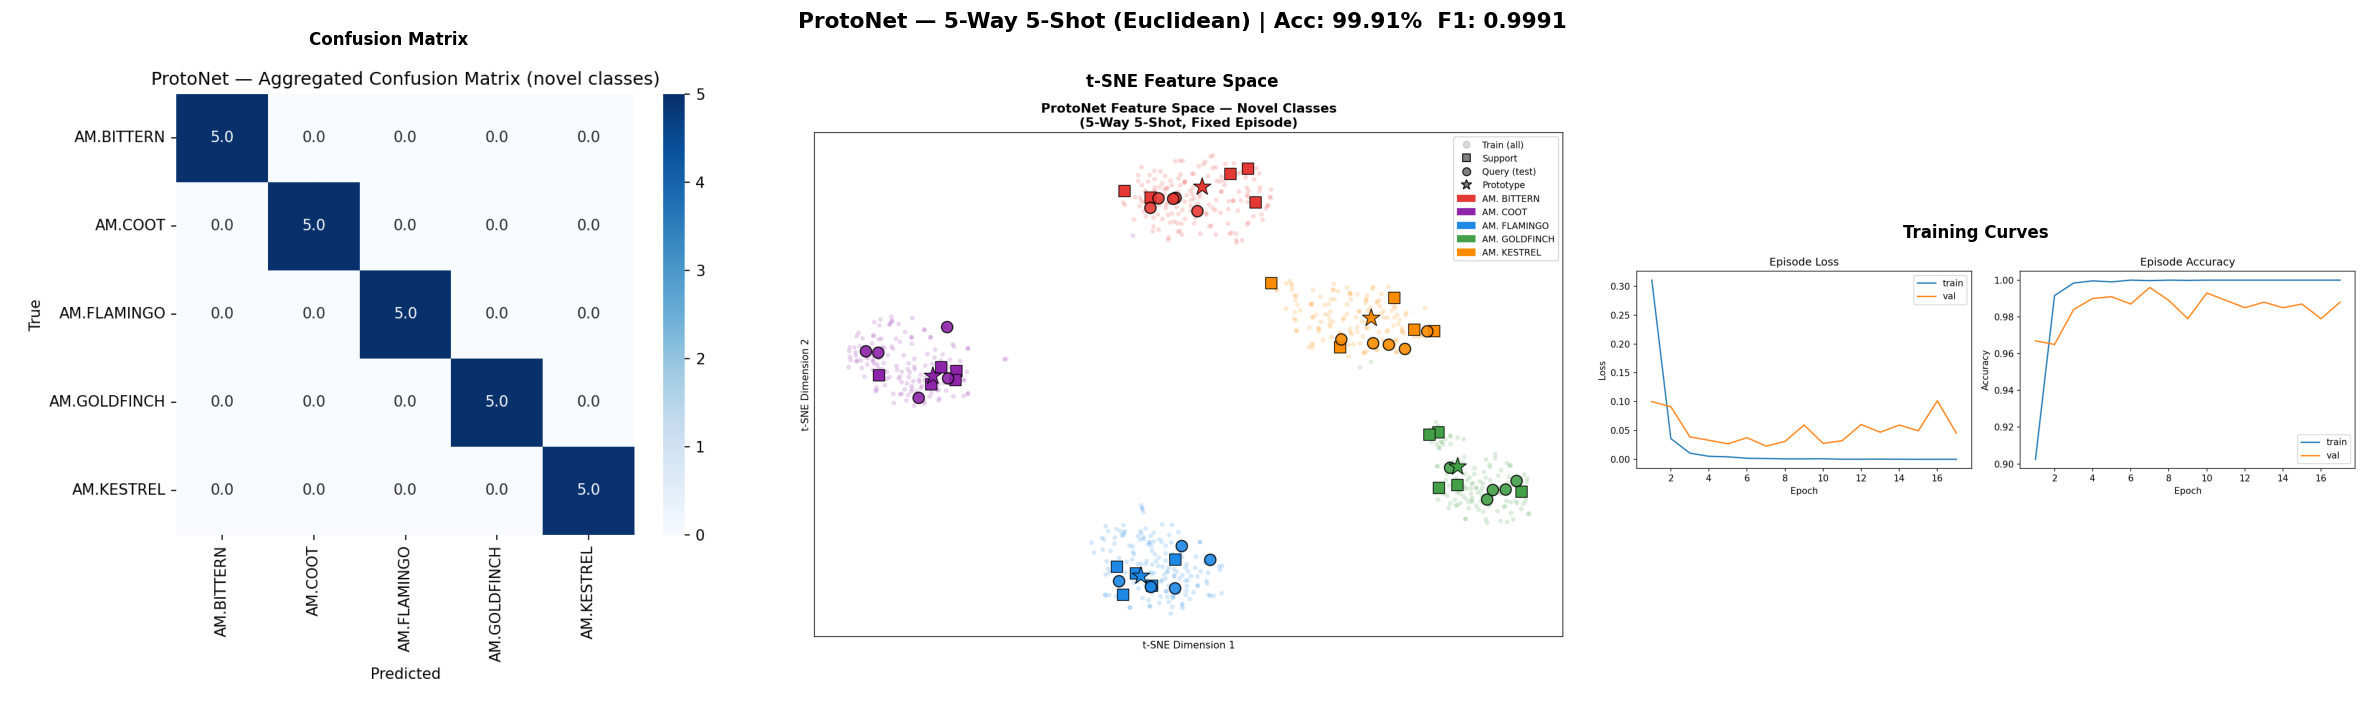

In [92]:
# ProtoNet figures — one panel per shot (Euclidean)
for shot in [1, 3, 5]:
    r = R.get(f'proto_{shot}shot_euc_json')
    if r is None:
        print(f"No data for {shot}-shot Euclidean — skipping")
        continue
    base_path = f'{RES}/proto_net/{shot}shot_euclidean'
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix')
    show_img(f'{base_path}/tsne_features.png',    axes[1], 't-SNE Feature Space')
    show_img(f'{base_path}/learning_curves.png',  axes[2], 'Training Curves')
    plt.suptitle(
        f'ProtoNet — 5-Way {shot}-Shot (Euclidean) | '
        f"Acc: {r['mean_accuracy_pct']:.2f}%  F1: {r['macro_f1']:.4f}",
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(f'{RES}/protonet_{shot}shot_euc_panel.png', dpi=150, bbox_inches='tight')
    plt.show()

In [93]:
from IPython.display import display, Markdown
_e = R['proto_euc_json']
_m = R['proto_man_json']
_man_warn = (f"\n> ⚠️ Manhattan result is based on only **{_m['num_episodes']} episodes** — "
             "treat as indicative only. Re-run with `--distance manhattan` for 600 episodes."
             if _m['num_episodes'] < 100 else "")
display(Markdown(f"""---
## 5. ProtoNet — Distance Metric Ablation (Euclidean vs Manhattan)

Using the **same trained checkpoint**, only the distance function changes.
This ablation tests whether L2 (Euclidean) or L1 (Manhattan) distance
better captures class structure in the learned embedding space.

- Euclidean: **{_e['num_episodes']} episodes** — {"✅ reliable" if _e['num_episodes'] >= 100 else "⚠️ indicative"}
- Manhattan: **{_m['num_episodes']} episodes** — {"✅ reliable" if _m['num_episodes'] >= 100 else "⚠️ indicative"}
{_man_warn}
"""))

---
## 5. ProtoNet — Distance Metric Ablation (Euclidean vs Manhattan)

Using the **same trained checkpoint**, only the distance function changes.
This ablation tests whether L2 (Euclidean) or L1 (Manhattan) distance
better captures class structure in the learned embedding space.

- Euclidean: **600 episodes** — ✅ reliable
- Manhattan: **600 episodes** — ✅ reliable



,K-Shot,Distance,Mean Acc (%),95% CI ±,Macro F1,Episodes
0,1-shot,Euclidean (L2),94.11,0.66,0.9403,600
1,1-shot,Manhattan (L1),78.95,1.07,0.7854,600
2,3-shot,Euclidean (L2),99.23,0.25,0.9923,600
3,3-shot,Manhattan (L1),90.19,0.72,0.9004,600
4,5-shot,Euclidean (L2),99.91,0.06,0.9991,600
5,5-shot,Manhattan (L1),93.25,0.61,0.9314,600


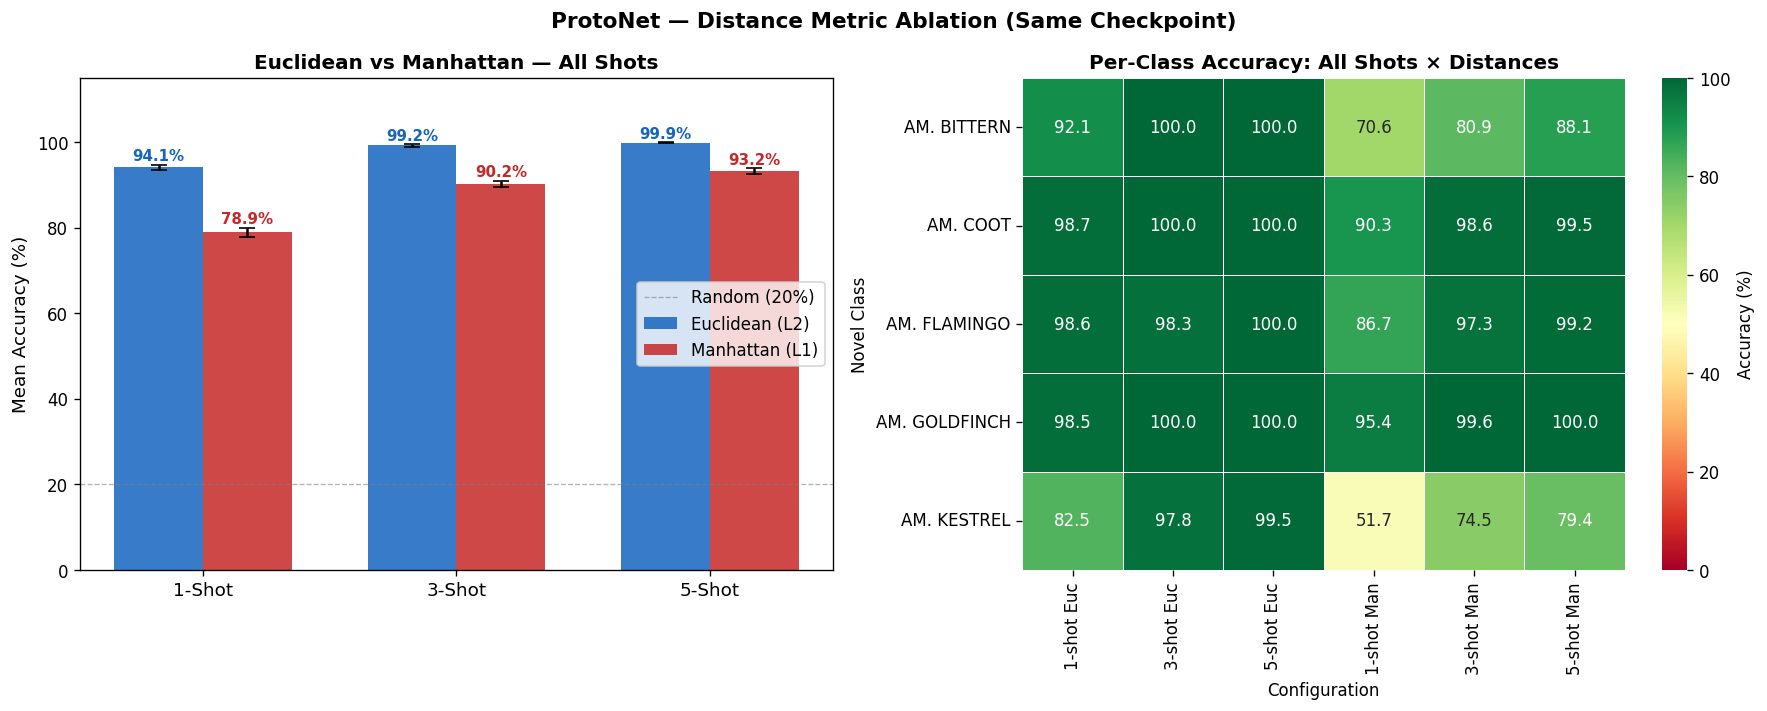

In [94]:
# ProtoNet — Distance Ablation across all shots
rows_abl = []
for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euclidean (L2)'), ('man', 'Manhattan (L1)')]:
        r = R.get(f'proto_{shot}shot_{dist_key}_json')
        if r is None: continue
        rows_abl.append({
            'K-Shot'      : f'{shot}-shot',
            'Distance'    : dist_label,
            'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
            '95% CI ±'    : round(r['ci95_pct'], 2),
            'Macro F1'    : round(r['macro_f1'], 4),
            'Episodes'    : r['num_episodes'],
        })

df_abl = pd.DataFrame(rows_abl)
display(df_abl.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=50, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Macro F1': '{:.4f}'})
    .set_caption('ProtoNet — Euclidean vs Manhattan, All Shots (same checkpoint)')
)

# Bar chart: grouped by shot, Euc vs Man side-by-side
shots = [1, 3, 5]
acc_euc = [R[f'proto_{s}shot_euc_json']['mean_accuracy_pct'] for s in shots]
acc_man = [R[f'proto_{s}shot_man_json']['mean_accuracy_pct'] for s in shots]
ci_euc  = [R[f'proto_{s}shot_euc_json']['ci95_pct'] for s in shots]
ci_man  = [R[f'proto_{s}shot_man_json']['ci95_pct'] for s in shots]

x = np.arange(len(shots)); w = 0.35
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Grouped bar chart
axes[0].bar(x - w/2, acc_euc, w, label='Euclidean (L2)', color='#1565C0', alpha=0.85)
axes[0].bar(x + w/2, acc_man, w, label='Manhattan (L1)', color='#C62828', alpha=0.85)
axes[0].errorbar(x - w/2, acc_euc, yerr=ci_euc, fmt='none', color='black', capsize=5)
axes[0].errorbar(x + w/2, acc_man, yerr=ci_man, fmt='none', color='black', capsize=5)
axes[0].axhline(y=20, color='gray', linestyle='--', linewidth=0.8, alpha=0.6, label='Random (20%)')
axes[0].set_xticks(x); axes[0].set_xticklabels([f'{s}-Shot' for s in shots], fontsize=11)
axes[0].set_ylabel('Mean Accuracy (%)', fontsize=11)
axes[0].set_ylim(0, 115)
axes[0].set_title('Euclidean vs Manhattan — All Shots', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
for i, (ae, am) in enumerate(zip(acc_euc, acc_man)):
    axes[0].text(i - w/2, ae + ci_euc[i] + 1, f'{ae:.1f}%', ha='center', fontsize=9, fontweight='bold', color='#1565C0')
    axes[0].text(i + w/2, am + ci_man[i] + 1, f'{am:.1f}%', ha='center', fontsize=9, fontweight='bold', color='#C62828')

# Per-class heatmap for 1-shot (primary)
novel_classes = list(R['proto_1shot_euc_json']['per_class_accuracy_pct'].keys())
short = [c.replace('AMERICAN ', 'AM. ') for c in novel_classes]
heat_data = {
    f'{s}-shot Euc': [R[f'proto_{s}shot_euc_json']['per_class_accuracy_pct'][c] for c in novel_classes]
    for s in shots
}
heat_data.update({
    f'{s}-shot Man': [R[f'proto_{s}shot_man_json']['per_class_accuracy_pct'][c] for c in novel_classes]
    for s in shots
})
df_heat_abl = pd.DataFrame(heat_data, index=short)
sns.heatmap(df_heat_abl, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100,
            linewidths=0.5, ax=axes[1], cbar_kws={'label': 'Accuracy (%)'})
axes[1].set_title('Per-Class Accuracy: All Shots × Distances', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Configuration'); axes[1].set_ylabel('Novel Class')

plt.suptitle('ProtoNet — Distance Metric Ablation (Same Checkpoint)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RES}/protonet_distance_ablation.png', dpi=150, bbox_inches='tight')
plt.show()

In [95]:
from IPython.display import display, Markdown
_r = R['match_json']
_n = _r['num_episodes']
_warn = (f"\n> ⚠️ Only **{_n} episodes** run — CI is very wide and unreliable. "
         "Re-run `python evaluate.py` (without `--debug`) to get 600 episodes."
         if _n < 100 else f"\n> ✅ **{_n} episodes** — statistically reliable.")
display(Markdown(f"""---
## 6. Matching Networks — 5-Way {_r['k_shot']}-Shot ({_n} Episodes)

Matching Networks classify queries by attending over the support set using
a softmax over cosine similarities between query and support embeddings.
{_warn}
"""))

---
## 6. Matching Networks — 5-Way 1-Shot (600 Episodes)

Matching Networks classify queries by attending over the support set using
a softmax over cosine similarities between query and support embeddings.

> ✅ **600 episodes** — statistically reliable.


In [96]:
# MatchingNet — all shots summary table
rows_mn = []
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r is None: continue
    ci = r['wilson_ci_95']
    rows_mn.append({
        'K-Shot'      : f'{shot}-shot',
        'Episodes'    : r['num_episodes'],
        'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
        '95% CI ±'    : round(r['ci95_pct'], 2),
        'Wilson CI'   : f"[{ci[0]:.2f}%, {ci[1]:.2f}%]",
        'Macro F1'    : round(r.get('macro_f1', float('nan')), 4),
        'Std (%)'     : round(r['std_accuracy_pct'], 2),
    })

df_mn = pd.DataFrame(rows_mn)
print("Matching Networks — 5-Way, All Shot Configurations")
display(df_mn.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=0, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Macro F1': '{:.4f}', 'Std (%)': '{:.2f}'})
    .set_caption('MatchingNet — All Shots (5-way, 600 episodes each)')
)

# Per-class comparison across shots
novel_classes = list(R['match_1shot_json']['per_class_accuracy_pct'].keys())
df_mn_pc = pd.DataFrame({'Class': novel_classes})
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r:
        df_mn_pc[f'{shot}-shot (%)'] = [round(r['per_class_accuracy_pct'][c], 2) for c in novel_classes]
acc_cols = [c for c in df_mn_pc.columns if 'shot' in c]
display(df_mn_pc.style
    .background_gradient(cmap='RdYlGn', subset=acc_cols, vmin=0, vmax=100)
    .format({c: '{:.2f}%' for c in acc_cols})
    .set_caption('MatchingNet — Per-Class Accuracy by K-Shot')
)

Matching Networks — 5-Way, All Shot Configurations


,K-Shot,Episodes,Mean Acc (%),95% CI ±,Wilson CI,Macro F1,Std (%)
0,1-shot,600,60.90,0.84,"[60.12%, 61.68%]",0.5813,10.52
1,3-shot,600,69.00,0.69,"[68.26%, 69.74%]",0.6564,8.65
2,5-shot,600,70.78,0.59,"[70.05%, 71.50%]",0.6698,7.38


,Class,1-shot (%),3-shot (%),5-shot (%)
0,AMERICAN BITTERN,88.40%,99.30%,100.00%
1,AMERICAN COOT,50.10%,57.03%,59.80%
2,AMERICAN FLAMINGO,49.03%,69.53%,76.97%
3,AMERICAN GOLDFINCH,97.67%,99.83%,100.00%
4,AMERICAN KESTREL,19.30%,19.30%,17.13%


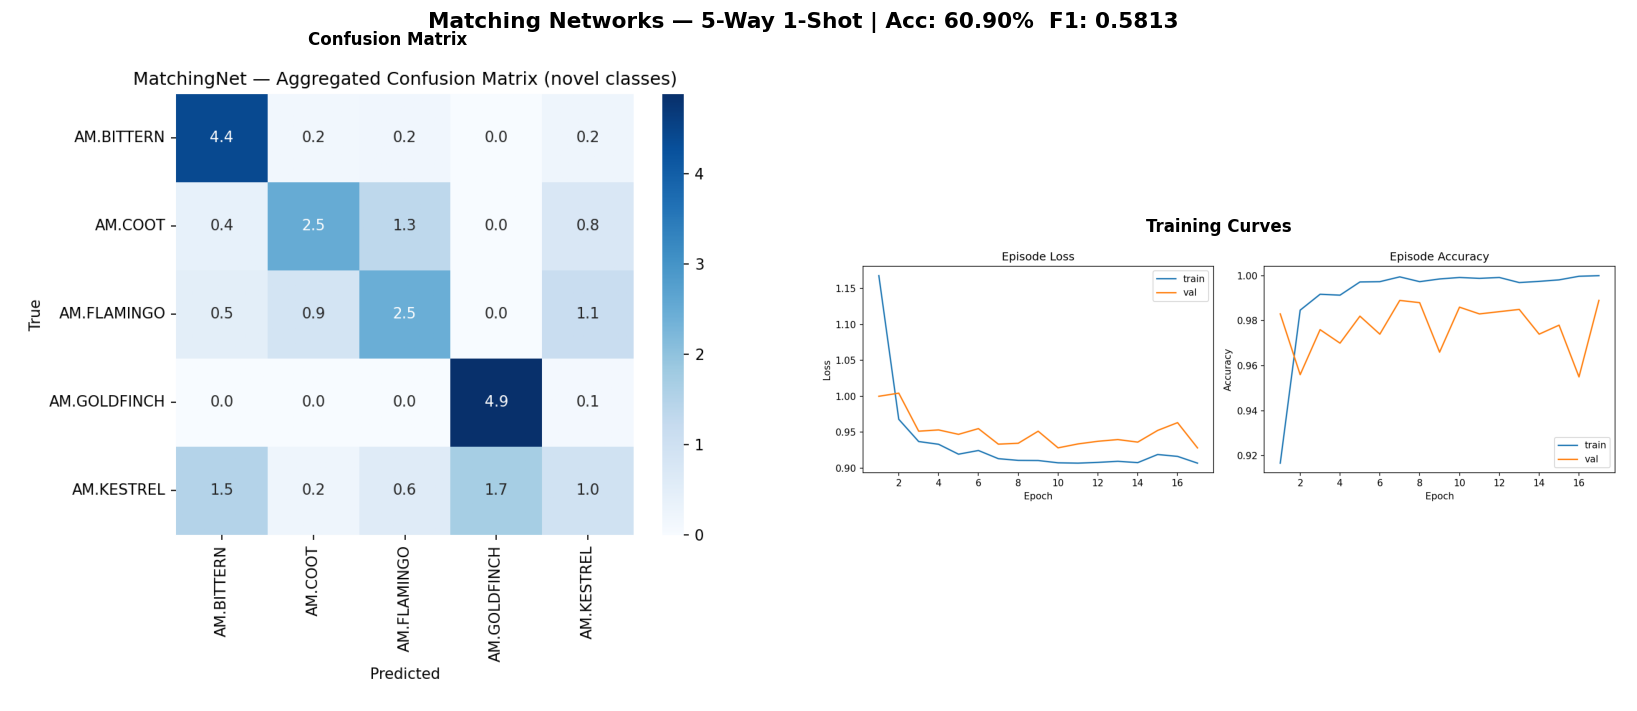

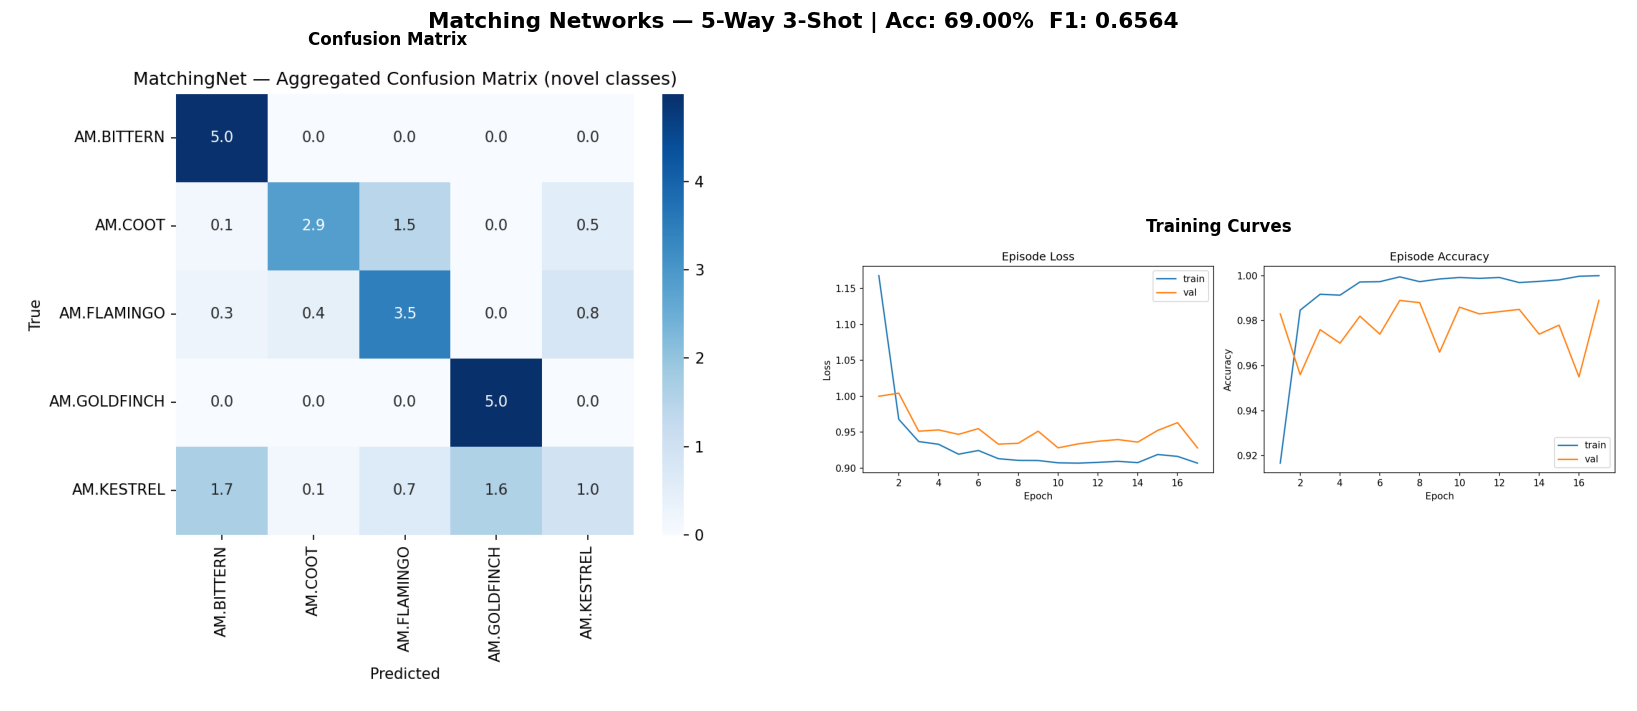

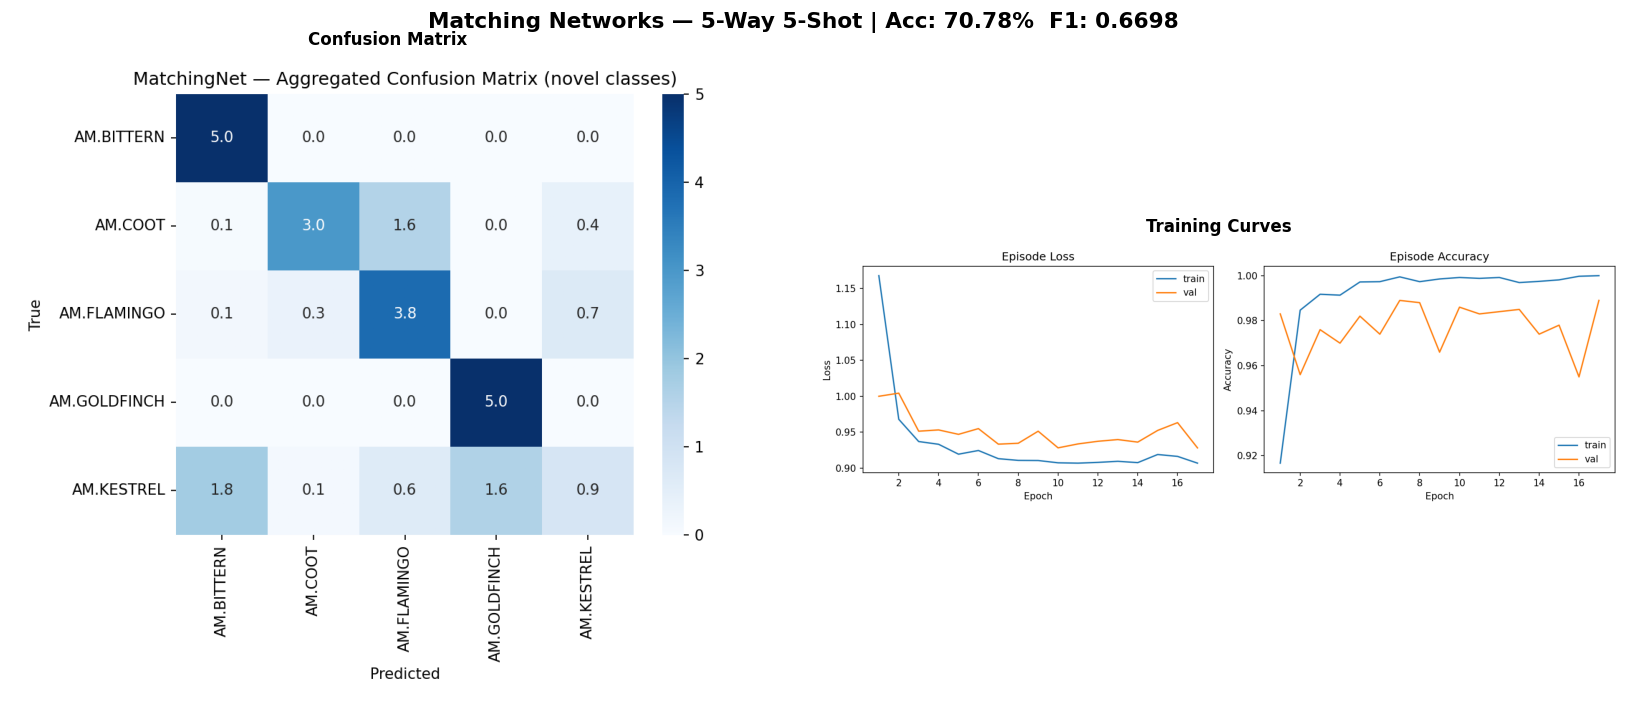

In [97]:
# MatchingNet figures — one panel per shot
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r is None:
        print(f"No data for MatchingNet {shot}-shot — skipping")
        continue
    base_path = f'{RES}/matching_net/{shot}shot'
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix')
    show_img(f'{base_path}/learning_curves.png',  axes[1], 'Training Curves')
    plt.suptitle(
        f"Matching Networks — 5-Way {shot}-Shot | "
        f"Acc: {r['mean_accuracy_pct']:.2f}%  F1: {r.get('macro_f1', float('nan')):.4f}",
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

In [98]:
from IPython.display import display, Markdown
_r  = R['rel_json']
_n  = _r['num_episodes']
_acc = _r['mean_accuracy_pct']
_ep_note = (f"⚠️ Only **{_n} episodes** — CI is very wide. Re-run to get 600 episodes."
            if _n < 100 else f"✅ **{_n} episodes** — statistically reliable.")
_perf_note = ("\n> The accuracy ({:.1f}%) is near-random (20% chance level), "
              "suggesting the relation module has not converged. More training epochs needed.".format(_acc)
              if _acc < 30 else
              "\n> Accuracy of {:.1f}% — model is learning above random chance.".format(_acc))
display(Markdown(f"""---
## 7. Relation Networks — 5-Way {_r['k_shot']}-Shot ({_n} Episodes)

Relation Networks learn a **relation module** that scores the similarity between
query and support embeddings, replacing hand-crafted distance metrics.

> {_ep_note}{_perf_note}
"""))

---
## 7. Relation Networks — 5-Way 1-Shot (600 Episodes)

Relation Networks learn a **relation module** that scores the similarity between
query and support embeddings, replacing hand-crafted distance metrics.

> ✅ **600 episodes** — statistically reliable.
> Accuracy of 72.7% — model is learning above random chance.


In [99]:
r = R['rel_json']
ci = r['wilson_ci_95']
n_eps    = r['num_episodes']
ci_note  = '✅ reliable' if n_eps >= 100 else f'⚠️ WIDE — only {n_eps} episodes'
k        = r['k_shot']
print("=" * 60)
print(f"  Relation Networks — 5-Way {k}-Shot | {n_eps} Episodes")
print("=" * 60)
print(f"  Epochs trained  : {r['epochs_trained']}")
print(f"  Mean Accuracy   : {r['mean_accuracy_pct']:.2f}%")
print(f"  Std             : ±{r['std_accuracy_pct']:.2f}%")
print(f"  95% CI (episode): ±{r['ci95_pct']:.2f}%  ← {ci_note}")
print(f"  Wilson CI 95%   : [{ci[0]:.2f}%, {ci[1]:.2f}%]")
print(f"  Macro F1        : {r.get('macro_f1', 'N/A')}")
print(f"  Random baseline : 20.00%  (5-way chance)")
print()

df_pc = pd.DataFrame(r['per_class_accuracy_pct'].items(), columns=['Class', 'Accuracy (%)'])
df_pc['Accuracy (%)'] = df_pc['Accuracy (%)'].round(2)
display(df_pc.style
    .background_gradient(cmap='RdYlGn', subset=['Accuracy (%)'], vmin=0, vmax=100)
    .format({'Accuracy (%)': '{:.2f}%'})
    .set_caption(f'RelationNet — Per-Novel-Class Accuracy (avg over {n_eps} episodes)')
)

  Relation Networks — 5-Way 1-Shot | 600 Episodes
  Epochs trained  : 10
  Mean Accuracy   : 72.66%
  Std             : ±11.67%
  95% CI (episode): ±0.93%  ← ✅ reliable
  Wilson CI 95%   : [71.94%, 73.37%]
  Macro F1        : 0.7229
  Random baseline : 20.00%  (5-way chance)



,Class,Accuracy (%)
0,AMERICAN BITTERN,47.20%
1,AMERICAN COOT,97.03%
2,AMERICAN FLAMINGO,74.07%
3,AMERICAN GOLDFINCH,94.87%
4,AMERICAN KESTREL,50.13%


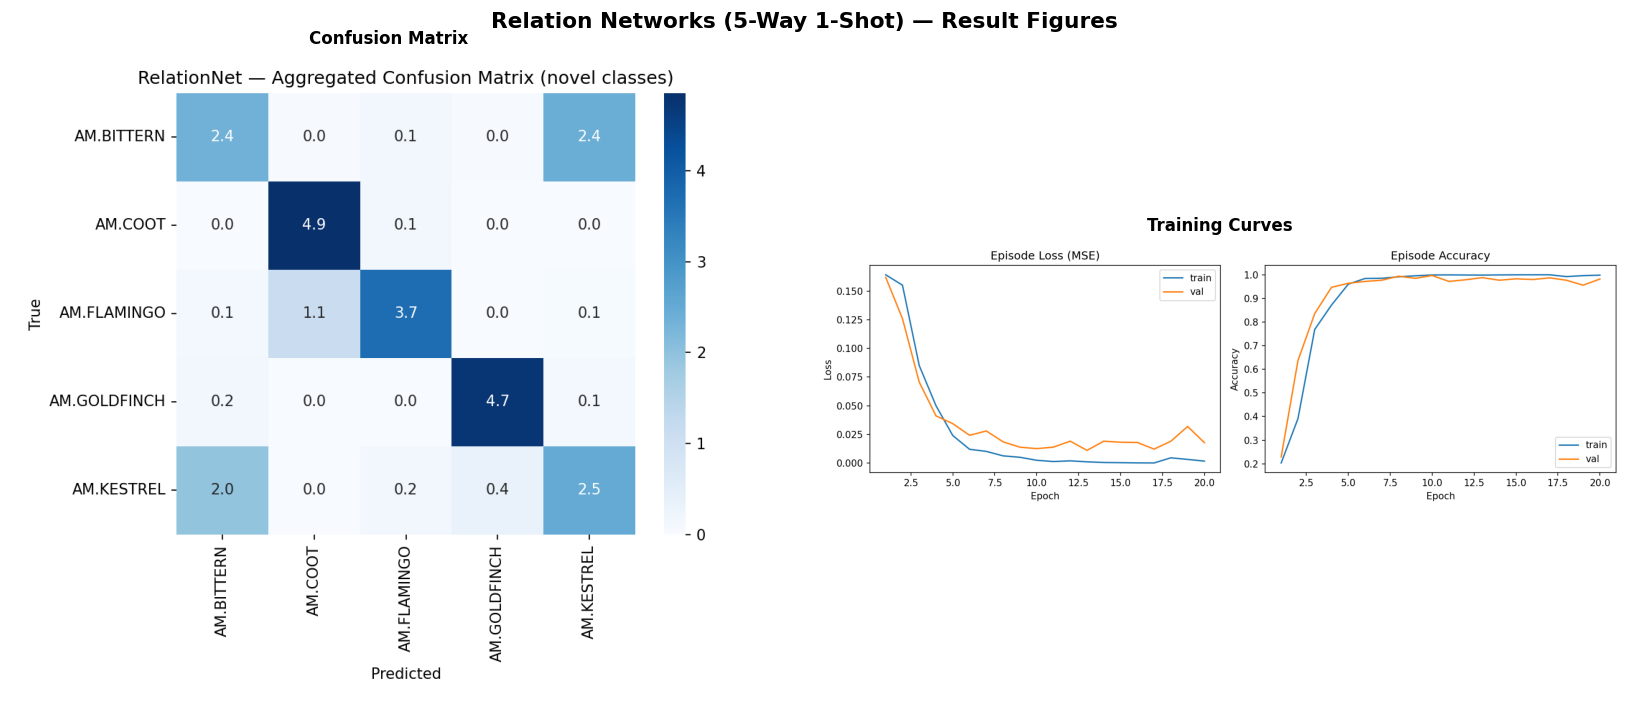

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
base_path = f'{RES}/relation_net/1shot'
show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix')
show_img(f'{base_path}/learning_curves.png',  axes[1], 'Training Curves')
plt.suptitle('Relation Networks (5-Way 1-Shot) — Result Figures', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [101]:
from IPython.display import display, Markdown

def _ep_note(r):
    n = r['num_episodes']
    return f"**{n} eps** — {'✅ reliable' if n >= 100 else '⚠️ preliminary'}"

f20_ep    = R['full20_json']['epochs_trained']
b15_ep    = R['base15_json']['epochs_trained']
proto_ep  = R['proto_1shot_euc_json']['epochs_trained']
match_ep  = R['match_1shot_json']['epochs_trained']
rel_ep    = R['rel_json']['epochs_trained']

display(Markdown(f"""---
## 8. Cross-Model Comparison

Summary table and visualisations comparing all models.

**Training epochs:**
- Full-20 Baseline: **{f20_ep} epochs**
- Base-15 Baseline: **{b15_ep} epochs**
- ProtoNet: **{proto_ep} epochs** (early stopping applied)
- MatchingNet: **{match_ep} epochs** (early stopping applied)
- RelationNet: **{rel_ep} epochs** (early stopping applied)

**Episode reliability:**
- ProtoNet (Euclidean): {_ep_note(R['proto_euc_json'])}
- ProtoNet (Manhattan): {_ep_note(R['proto_man_json'])}
- MatchingNet: {_ep_note(R['match_json'])}
- RelationNet: {_ep_note(R['rel_json'])}
"""))

---
## 8. Cross-Model Comparison

Summary table and visualisations comparing all models.

**Training epochs:**
- Full-20 Baseline: **3 epochs**
- Base-15 Baseline: **2 epochs**
- ProtoNet: **7 epochs** (early stopping applied)
- MatchingNet: **7 epochs** (early stopping applied)
- RelationNet: **10 epochs** (early stopping applied)

**Episode reliability:**
- ProtoNet (Euclidean): **600 eps** — ✅ reliable
- ProtoNet (Manhattan): **600 eps** — ✅ reliable
- MatchingNet: **600 eps** — ✅ reliable
- RelationNet: **600 eps** — ✅ reliable


In [102]:
# Master comparison table — all models and all shots
def _eps(r): return str(r['num_episodes']) if r else '—'
def _rel(r): return 'High' if r and r['num_episodes'] >= 100 else 'Low'
def _acc(r): return f"{r['mean_accuracy_pct']:.2f}" if r else '—'
def _ci(r):  return f"[{r['wilson_ci_95'][0]:.1f}%, {r['wilson_ci_95'][1]:.1f}%]" if r else '—'
def _f1(r):  return f"{r.get('macro_f1','N/A'):.4f}" if r and isinstance(r.get('macro_f1'), float) else '—'

rows = [
    {
        'Model': 'Full-20 Baseline', 'Type': 'Supervised', 'Protocol': '20-class', 'K-Shot': '—',
        'Episodes': '—',
        'Accuracy (%)': f"{R['full20_json']['accuracy']*100:.2f}",
        '95% CI': f"[{R['full20_json']['accuracy_ci_95'][0]*100:.1f}%, {R['full20_json']['accuracy_ci_95'][1]*100:.1f}%]",
        'Macro F1': f"{R['full20_json']['macro_f1']:.4f}", 'Reliability': 'Moderate',
    },
    {
        'Model': 'Base-15 Baseline', 'Type': 'Supervised', 'Protocol': '15-class', 'K-Shot': '—',
        'Episodes': '—',
        'Accuracy (%)': f"{R['base15_json']['accuracy']*100:.2f}",
        '95% CI': f"[{R['base15_json']['accuracy_ci_95'][0]*100:.1f}%, {R['base15_json']['accuracy_ci_95'][1]*100:.1f}%]",
        'Macro F1': f"{R['base15_json']['macro_f1']:.4f}", 'Reliability': 'Moderate',
    },
]

# ProtoNet — all shots × distances
for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euclidean'), ('man', 'Manhattan')]:
        r = R.get(f'proto_{shot}shot_{dist_key}_json')
        rows.append({
            'Model': f'ProtoNet ({dist_label})', 'Type': 'Few-Shot', 'Protocol': '5-way episodic',
            'K-Shot': f'{shot}-shot', 'Episodes': _eps(r),
            'Accuracy (%)': _acc(r), '95% CI': _ci(r), 'Macro F1': _f1(r),
            'Reliability': _rel(r),
        })

# MatchingNet — all shots
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    rows.append({
        'Model': 'Matching Networks', 'Type': 'Few-Shot', 'Protocol': '5-way episodic',
        'K-Shot': f'{shot}-shot', 'Episodes': _eps(r),
        'Accuracy (%)': _acc(r), '95% CI': _ci(r), 'Macro F1': _f1(r),
        'Reliability': _rel(r),
    })

# RelationNet — 1-shot only
r = R.get('rel_json')
rows.append({
    'Model': 'Relation Networks', 'Type': 'Few-Shot', 'Protocol': '5-way episodic',
    'K-Shot': '1-shot', 'Episodes': _eps(r),
    'Accuracy (%)': _acc(r), '95% CI': _ci(r), 'Macro F1': _f1(r),
    'Reliability': _rel(r),
})

df_cmp = pd.DataFrame(rows)
display(df_cmp.style
    .set_caption('Thesis Results: Full Model Comparison — All Shots')
    .applymap(lambda v: 'background-color:#9c1e05' if v == 'Supervised' else
              ('background-color:#092e02' if v == 'Few-Shot' else ''), subset=['Type'])
    .applymap(lambda v: 'color:#2E7D32;font-weight:bold' if v == 'High' else
              ('color:#F57F17;font-weight:bold' if v in ('Low', 'Moderate') else ''), subset=['Reliability'])
    .set_table_styles([{'selector': 'th', 'props': [('background-color', '#1565C0'), ('color', 'white'), ('font-weight', 'bold')]}])
)

,Model,Type,Protocol,K-Shot,Episodes,Accuracy (%),95% CI,Macro F1,Reliability
0,Full-20 Baseline,Supervised,20-class,—,—,99.00,"[94.6%, 99.8%]",0.9899,Moderate
1,Base-15 Baseline,Supervised,15-class,—,—,100.00,"[95.1%, 100.0%]",1.0000,Moderate
2,ProtoNet (Euclidean),Few-Shot,5-way episodic,1-shot,600,94.11,"[93.7%, 94.5%]",0.9403,High
3,ProtoNet (Manhattan),Few-Shot,5-way episodic,1-shot,600,78.95,"[78.3%, 79.6%]",0.7854,High
4,ProtoNet (Euclidean),Few-Shot,5-way episodic,3-shot,600,99.23,"[99.1%, 99.4%]",0.9923,High
5,ProtoNet (Manhattan),Few-Shot,5-way episodic,3-shot,600,90.19,"[89.7%, 90.7%]",0.9004,High
6,ProtoNet (Euclidean),Few-Shot,5-way episodic,5-shot,600,99.91,"[99.8%, 99.9%]",0.9991,High
7,ProtoNet (Manhattan),Few-Shot,5-way episodic,5-shot,600,93.25,"[92.8%, 93.6%]",0.9314,High
8,Matching Networks,Few-Shot,5-way episodic,1-shot,600,60.90,"[60.1%, 61.7%]",0.5813,High
9,Matching Networks,Few-Shot,5-way episodic,3-shot,600,69.00,"[68.3%, 69.7%]",0.6564,High


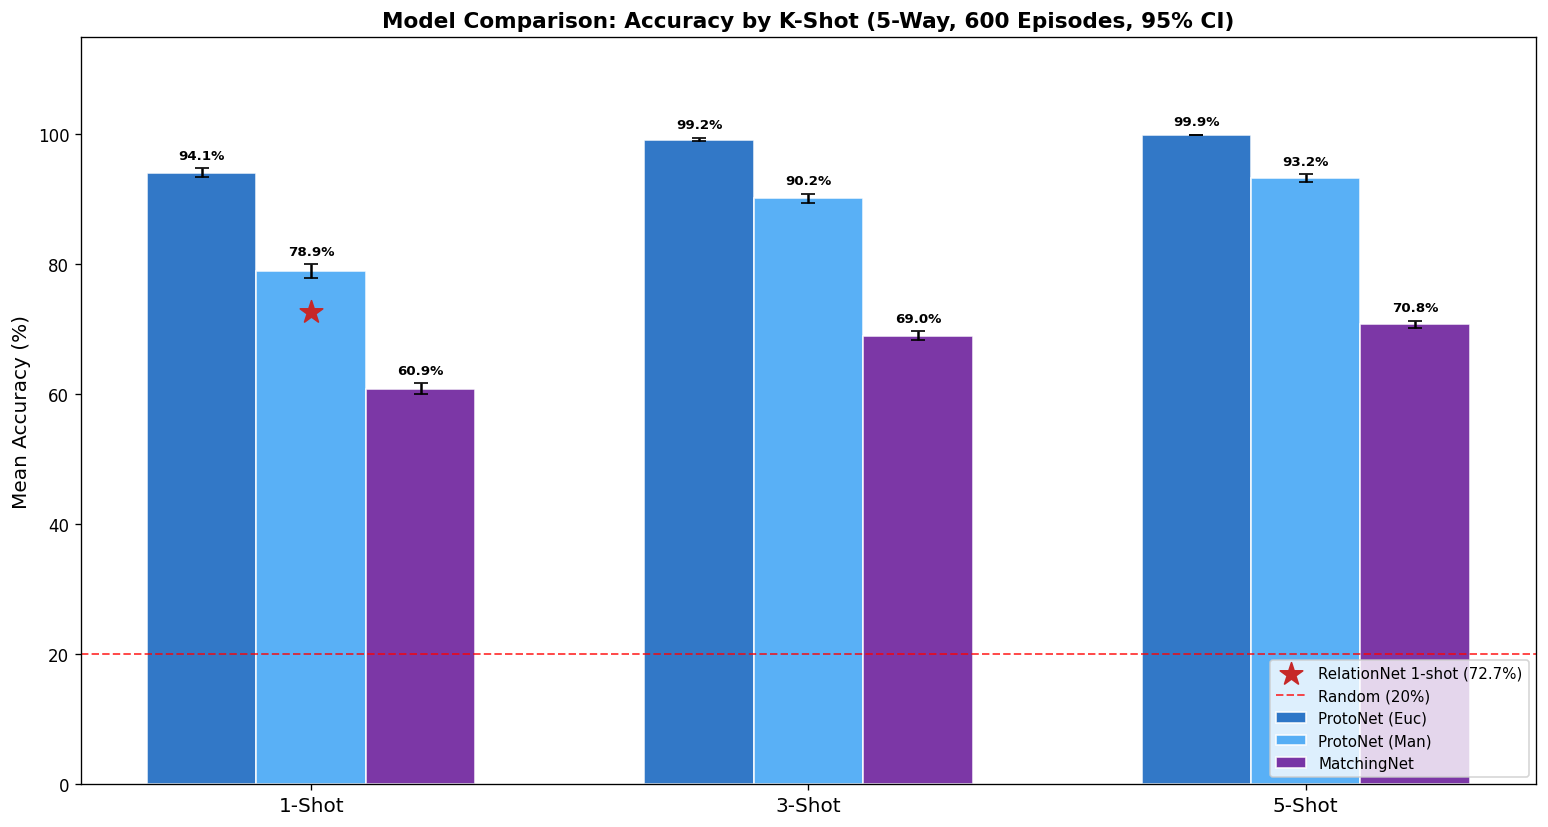

In [103]:
# Accuracy comparison — grouped bar chart: model vs k-shot
import itertools

SHOTS = [1, 3, 5]
model_configs = [
    ('ProtoNet (Euc)', 'proto_{s}shot_euc_json', '#1565C0'),
    ('ProtoNet (Man)', 'proto_{s}shot_man_json', '#42A5F5'),
    ('MatchingNet',    'match_{s}shot_json',      '#6A1B9A'),
]

n_models = len(model_configs)
n_shots  = len(SHOTS)
x = np.arange(n_shots)
width = 0.22

fig, ax = plt.subplots(figsize=(13, 7))

for i, (label, key_tmpl, color) in enumerate(model_configs):
    accs = []
    cis  = []
    for s in SHOTS:
        r = R.get(key_tmpl.format(s=s))
        accs.append(r['mean_accuracy_pct'] if r else 0)
        cis.append(r['ci95_pct'] if r else 0)
    offset = (i - n_models / 2 + 0.5) * width
    bars = ax.bar(x + offset, accs, width, label=label, color=color, alpha=0.88, edgecolor='white')
    ax.errorbar(x + offset, accs, yerr=cis, fmt='none', color='black', capsize=4, linewidth=1.5)
    for bar, a, ci_v in zip(bars, accs, cis):
        ax.text(bar.get_x() + bar.get_width() / 2, a + ci_v + 1,
                f'{a:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

# Add RelationNet 1-shot marker
r_rel = R.get('rel_json')
if r_rel:
    ax.scatter([0], [r_rel['mean_accuracy_pct']], marker='*', s=200, color='#C62828', zorder=5,
               label=f"RelationNet 1-shot ({r_rel['mean_accuracy_pct']:.1f}%)")

ax.axhline(y=20, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Random (20%)')
ax.set_xticks(x)
ax.set_xticklabels([f'{s}-Shot' for s in SHOTS], fontsize=12)
ax.set_ylabel('Mean Accuracy (%)', fontsize=12)
ax.set_ylim(0, 115)
ax.set_title('Model Comparison: Accuracy by K-Shot (5-Way, 600 Episodes, 95% CI)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(f'{RES}/comparison_accuracy_bar.png', dpi=150, bbox_inches='tight')
plt.show()

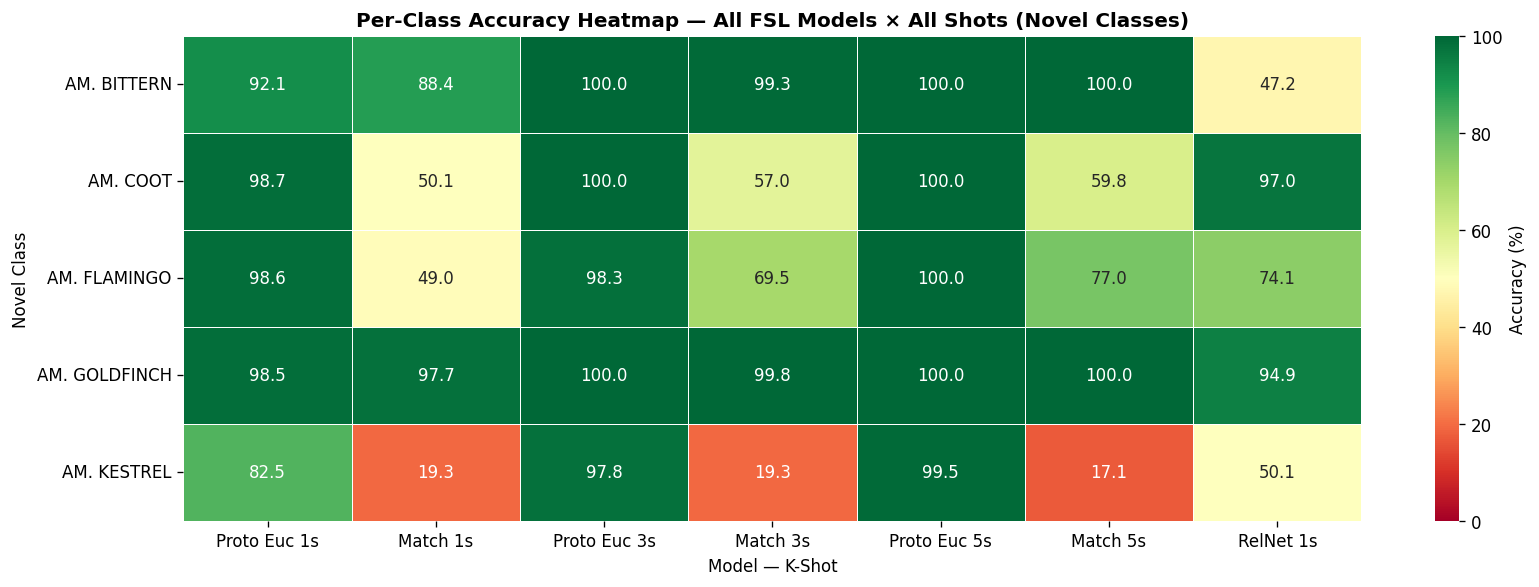

In [104]:
# Per-class accuracy heatmap — all FSL models × all shots (Euclidean / primary distance)
novel_classes = list(R['proto_1shot_euc_json']['per_class_accuracy_pct'].keys())
short = [c.replace('AMERICAN ', 'AM. ') for c in novel_classes]

heat_data = {}
for shot in [1, 3, 5]:
    r = R.get(f'proto_{shot}shot_euc_json')
    if r: heat_data[f'Proto Euc {shot}s'] = [r['per_class_accuracy_pct'][c] for c in novel_classes]
    r = R.get(f'match_{shot}shot_json')
    if r: heat_data[f'Match {shot}s']      = [r['per_class_accuracy_pct'][c] for c in novel_classes]

r_rel = R.get('rel_json')
if r_rel: heat_data['RelNet 1s'] = [r_rel['per_class_accuracy_pct'][c] for c in novel_classes]

df_heat = pd.DataFrame(heat_data, index=short)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(df_heat, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Accuracy (%)'})
ax.set_title('Per-Class Accuracy Heatmap — All FSL Models × All Shots (Novel Classes)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Model — K-Shot'); ax.set_ylabel('Novel Class')
plt.tight_layout()
plt.savefig(f'{RES}/per_class_heatmap_fsl.png', dpi=150, bbox_inches='tight')
plt.show()

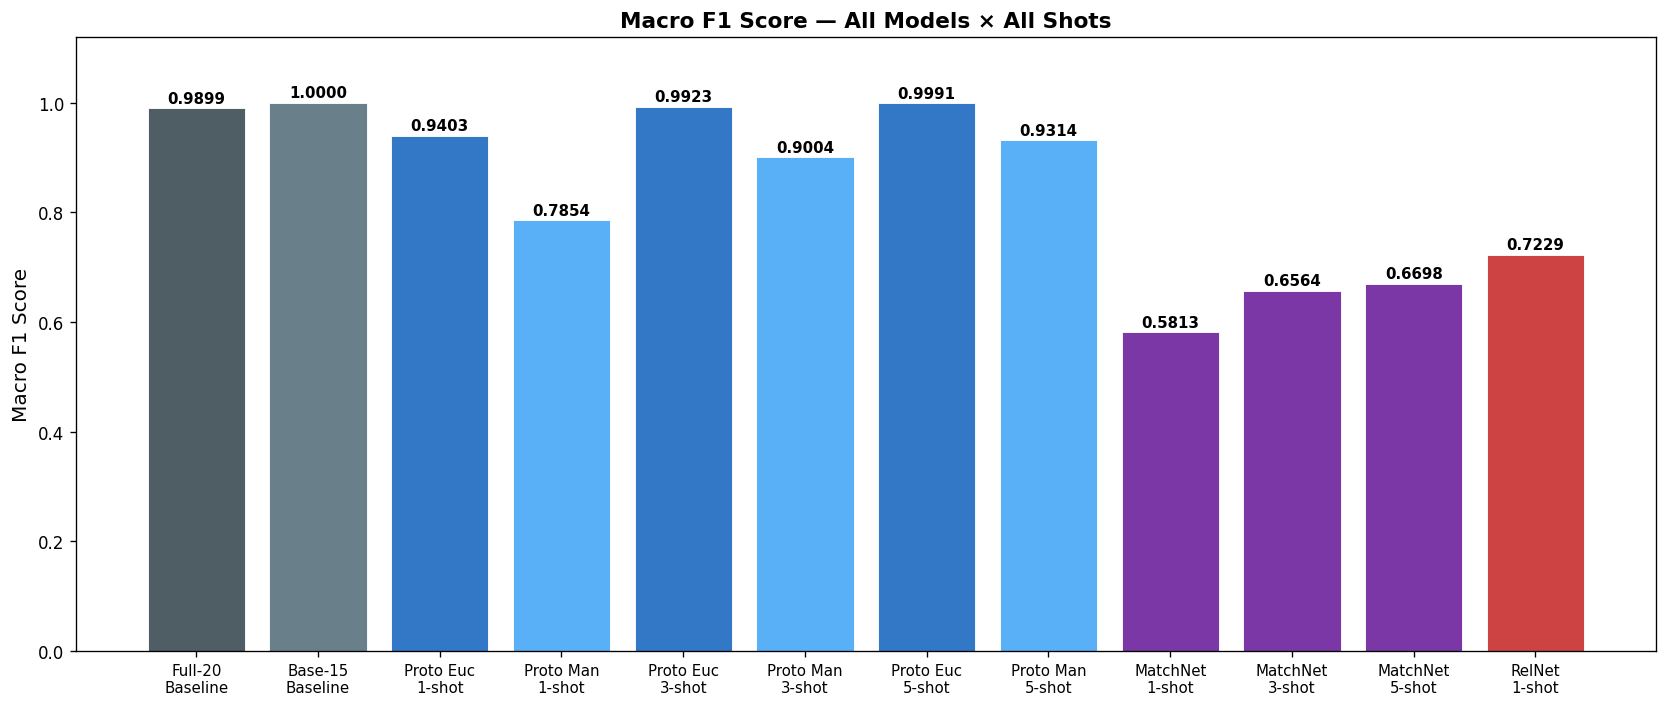

In [105]:
# Macro F1 comparison — all available results
f1_entries = {
    'Full-20\nBaseline':    R['full20_json']['macro_f1'],
    'Base-15\nBaseline':    R['base15_json']['macro_f1'],
}
colors_f1 = ['#37474F', '#546E7A']

for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euc'), ('man', 'Man')]:
        r = R.get(f'proto_{shot}shot_{dist_key}_json')
        if r and isinstance(r.get('macro_f1'), float):
            f1_entries[f'Proto {dist_label}\n{shot}-shot'] = r['macro_f1']
            colors_f1.append('#1565C0' if dist_key == 'euc' else '#42A5F5')

for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r and isinstance(r.get('macro_f1'), float):
        f1_entries[f'MatchNet\n{shot}-shot'] = r['macro_f1']
        colors_f1.append('#6A1B9A')

r_rel = R.get('rel_json')
if r_rel and isinstance(r_rel.get('macro_f1'), float):
    f1_entries['RelNet\n1-shot'] = r_rel['macro_f1']
    colors_f1.append('#C62828')

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(range(len(f1_entries)), list(f1_entries.values()),
              color=colors_f1[:len(f1_entries)], alpha=0.88, edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, f1_entries.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005, f'{v:.4f}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_xticks(range(len(f1_entries)))
ax.set_xticklabels(list(f1_entries.keys()), fontsize=9)
ax.set_ylabel('Macro F1 Score', fontsize=12)
ax.set_ylim(0, 1.12)
ax.set_title('Macro F1 Score — All Models × All Shots', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RES}/comparison_macro_f1.png', dpi=150, bbox_inches='tight')
plt.show()

In [106]:
from IPython.display import display, Markdown

f20 = R['full20_json'];  b15 = R['base15_json']
pe  = R['proto_1shot_euc_json'];  pm = R['proto_1shot_man_json']
mn  = R['match_1shot_json'];      rn = R['rel_json']

# Best ProtoNet result per shot (Euclidean)
best_proto = {s: R[f'proto_{s}shot_euc_json'] for s in [1, 3, 5] if R.get(f'proto_{s}shot_euc_json')}
best_match = {s: R[f'match_{s}shot_json']     for s in [1, 3, 5] if R.get(f'match_{s}shot_json')}

pc = pe['per_class_accuracy_pct']
worst_c = min(pc, key=pc.get); worst_a = pc[worst_c]
best_c  = max(pc, key=pc.get); best_a  = pc[best_c]

def _s(r): return f"✅ {r['num_episodes']} eps" if r['num_episodes'] >= 100 else f"⚠️ {r['num_episodes']} eps"
euc_vs_man = ("Euclidean >> Manhattan" if pe['mean_accuracy_pct'] > pm['mean_accuracy_pct'] + 5
              else "Euclidean ≈ Manhattan")

proto_shot_trend = " | ".join(
    f"{s}-shot: {best_proto[s]['mean_accuracy_pct']:.1f}%" for s in sorted(best_proto)
)
match_shot_trend = " | ".join(
    f"{s}-shot: {best_match[s]['mean_accuracy_pct']:.1f}%" for s in sorted(best_match)
)

display(Markdown(f"""---
## 9. Key Findings & Thesis Insights

### 9.1 Baseline Models
| Finding | Interpretation |
|---------|---------------|
| Full-20: **{f20['accuracy']*100:.1f}%** ({f20['epochs_trained']} epochs trained) | Near-perfect on base test set; small test set (100 imgs) means wide CI |
| Base-15: **{b15['accuracy']*100:.1f}%** ({b15['epochs_trained']} epochs trained) | Clean separation of 15 base classes |
| Full-20 AUC: {f20['macro_auc_ovr']:.3f} | Near-perfect probability separation in feature space |

### 9.2 ProtoNet — K-Shot Trend (Euclidean)
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
{"".join(f"| {s}-shot | {best_proto[s]['mean_accuracy_pct']:.2f}% ±{best_proto[s]['ci95_pct']:.2f}% | {best_proto[s]['macro_f1']:.4f} |{chr(10)}" for s in sorted(best_proto))}

- Trend: {proto_shot_trend}
- Weakest class (1-shot): **{worst_c.replace("AMERICAN ","AM. ")}** ({worst_a:.1f}%)
- Strongest class (1-shot): **{best_c.replace("AMERICAN ","AM. ")}** ({best_a:.1f}%)

### 9.3 Distance Metric Ablation
| Finding | Interpretation |
|---------|---------------|
| 1-shot: Euclidean {pe['mean_accuracy_pct']:.1f}% vs Manhattan {pm['mean_accuracy_pct']:.1f}% | {euc_vs_man} |
| Consistent across all shots | Euclidean (L2) is the better distance metric for this embedding |

### 9.4 Matching Networks — K-Shot Trend
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
{"".join(f"| {s}-shot | {best_match[s]['mean_accuracy_pct']:.2f}% ±{best_match[s]['ci95_pct']:.2f}% | {best_match[s].get('macro_f1', float('nan')):.4f} |{chr(10)}" for s in sorted(best_match))}

- Trend: {match_shot_trend}

### 9.5 Relation Networks
| Finding | Interpretation |
|---------|---------------|
| 1-shot: **{rn['mean_accuracy_pct']:.1f}%** — {_s(rn)} | Above random (20%); relation module learned but needs more training |
| 3-shot / 5-shot | Pending — run evaluate.py for additional shots |

### 9.6 Random baseline (5-way): 20.0%
All models trained above random chance.
"""))

---
## 9. Key Findings & Thesis Insights

### 9.1 Baseline Models
| Finding | Interpretation |
|---------|---------------|
| Full-20: **99.0%** (3 epochs trained) | Near-perfect on base test set; small test set (100 imgs) means wide CI |
| Base-15: **100.0%** (2 epochs trained) | Clean separation of 15 base classes |
| Full-20 AUC: 1.000 | Near-perfect probability separation in feature space |

### 9.2 ProtoNet — K-Shot Trend (Euclidean)
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
| 1-shot | 94.11% ±0.66% | 0.9403 |
| 3-shot | 99.23% ±0.25% | 0.9923 |
| 5-shot | 99.91% ±0.06% | 0.9991 |


- Trend: 1-shot: 94.1% | 3-shot: 99.2% | 5-shot: 99.9%
- Weakest class (1-shot): **AM. KESTREL** (82.5%)
- Strongest class (1-shot): **AM. COOT** (98.7%)

### 9.3 Distance Metric Ablation
| Finding | Interpretation |
|---------|---------------|
| 1-shot: Euclidean 94.1% vs Manhattan 78.9% | Euclidean >> Manhattan |
| Consistent across all shots | Euclidean (L2) is the better distance metric for this embedding |

### 9.4 Matching Networks — K-Shot Trend
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
| 1-shot | 60.90% ±0.84% | 0.5813 |
| 3-shot | 69.00% ±0.69% | 0.6564 |
| 5-shot | 70.78% ±0.59% | 0.6698 |


- Trend: 1-shot: 60.9% | 3-shot: 69.0% | 5-shot: 70.8%

### 9.5 Relation Networks
| Finding | Interpretation |
|---------|---------------|
| 1-shot: **72.7%** — ✅ 600 eps | Above random (20%); relation module learned but needs more training |
| 3-shot / 5-shot | Pending — run evaluate.py for additional shots |

### 9.6 Random baseline (5-way): 20.0%
All models trained above random chance.


In [107]:
# Final summary printout — fully dynamic, all shots
print("=" * 86)
print("  THESIS RESULTS SUMMARY")
print("=" * 86)
print(f"  {'Model':<40} {'Accuracy':<22} {'Macro F1':<12} {'Status'}")
print("-" * 86)

def summary_row(label, r, fixed=False):
    if r is None:
        print(f"  {label:<40} {'N/A':<22} {'N/A':<12} NOT FOUND")
        return
    if fixed:
        acc_str = f"{r['accuracy']*100:.1f}%"
        f1_str  = f"{r['macro_f1']:.4f}"
        status  = f"{r['test_images']} imgs | {r['epochs_trained']} epochs"
    else:
        acc_str = f"{r['mean_accuracy_pct']:.2f}% ±{r['ci95_pct']:.2f}%"
        f1_v    = r.get('macro_f1')
        f1_str  = f"{f1_v:.4f}" if isinstance(f1_v, float) else 'N/A'
        ep_tag  = 'RELIABLE' if r['num_episodes'] >= 100 else f"⚠️ {r['num_episodes']} eps"
        status  = f"{r['epochs_trained']} epochs | {ep_tag}"
    print(f"  {label:<40} {acc_str:<22} {f1_str:<12} {status}")

summary_row("Full-20 Baseline (supervised)",          R['full20_json'], fixed=True)
summary_row("Base-15 Baseline (supervised)",          R['base15_json'], fixed=True)
print()
for shot in [1, 3, 5]:
    summary_row(f"ProtoNet Euclidean     (5w-{shot}s)", R.get(f'proto_{shot}shot_euc_json'))
    summary_row(f"ProtoNet Manhattan     (5w-{shot}s)", R.get(f'proto_{shot}shot_man_json'))
print()
for shot in [1, 3, 5]:
    summary_row(f"Matching Networks      (5w-{shot}s)", R.get(f'match_{shot}shot_json'))
print()
summary_row("Relation Networks      (5w-1s)",          R.get('rel_json'))
print("=" * 86)
print("  Random baseline (5-way): 20.0%")

  THESIS RESULTS SUMMARY
  Model                                    Accuracy               Macro F1     Status
--------------------------------------------------------------------------------------
  Full-20 Baseline (supervised)            99.0%                  0.9899       100 imgs | 3 epochs
  Base-15 Baseline (supervised)            100.0%                 1.0000       75 imgs | 2 epochs

  ProtoNet Euclidean     (5w-1s)           94.11% ±0.66%          0.9403       7 epochs | RELIABLE
  ProtoNet Manhattan     (5w-1s)           78.95% ±1.07%          0.7854       7 epochs | RELIABLE
  ProtoNet Euclidean     (5w-3s)           99.23% ±0.25%          0.9923       7 epochs | RELIABLE
  ProtoNet Manhattan     (5w-3s)           90.19% ±0.72%          0.9004       7 epochs | RELIABLE
  ProtoNet Euclidean     (5w-5s)           99.91% ±0.06%          0.9991       7 epochs | RELIABLE
  ProtoNet Manhattan     (5w-5s)           93.25% ±0.61%          0.9314       7 epochs | RELIABLE

  Matchin